<a href="https://www.kaggle.com/code/engrataurrahman/real-time-bd-grid-risk-assesment-with-expai?scriptVersionId=356811208" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

## Introduction and Pipeline of the project:

A physics-informed stacking ensemble architecture combining CatBoost, XGBoost, and Ridge Regression for dynamic multi-output fault classification and severity assessment in power distribution grids.

```text
===================================================================================================
                                      SYSTEM ARCHITECTURE PIPELINE                                 
===================================================================================================

       [ Raw Grid Dataset (CSV) ]
                   │
                   ▼
  1️⃣  ┌──────────────────────────┐
      │   Data Loading & EDA     │ ──► Inspect Missing Values, Schema & Data Types
      └──────────────────────────┘
                   │
                   ▼
  2️⃣  ┌──────────────────────────┐
      │ Physics Feature Pipeline │ ──► Compute S (kVA), Z (Ω), PF Mismatch & Power Ratios
      └──────────────────────────┘
                   │
                   ▼
  3️⃣  ┌──────────────────────────┐
      │ Preprocessing & Splitting│ ──► Target Encoding, Feature Scaling (StandardScaler)
      └──────────────────────────┘     & Train-Test Split (80/20)
                   │
                   ▼
  4️⃣  ┌──────────────────────────┐
      │ From 8 model Best Base Models Training    │ ──► Train CatBoost Classifier & XGBoost Classifier
      └──────────────────────────┘
                   │
                   ▼
  5️⃣  ┌──────────────────────────┐
      │  Hyperparameter Tuning   │ ──► Optimize Base Models for Performance Stability
      └──────────────────────────┘
                   │
                   ▼
  6️⃣  ┌──────────────────────────┐
      │    Stacking Ensemble     │ ──► Combine Base Predictions via Meta-Learner
      └──────────────────────────┘     (RidgeClassifier) for Multi-Output Target
                   │
                   ▼
  7️⃣  ┌──────────────────────────┐
      │  Artifact Serialization  │ ──► Save Models, Scaler & Encoders as .pkl Files
      └──────────────────────────┘
                   │
                   ▼
  8️⃣  ┌──────────────────────────┐
      │   Visual Analytics       │ ──► Side-by-Side Confusion Matrices & Precision/
      └──────────────────────────┘     Recall Heatmaps for Grid Status & Fault Severity

===================================================================================================
```

## Setup

In [8]:
# ─── Install Dependencies ───
!pip install -q xgboost lightgbm catboost

In [9]:
#from google.colab import drive

#drive.mount("/content/drive")

In [10]:
# ─── Imports ───
import warnings, time, gc
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ─── Plot Configuration ───
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})
SEED = 42
np.random.seed(SEED)

print("Environment ready.")

Environment ready.


## 2. Data Loading and Exploring

In [11]:
# ─── Load Dataset ───
raw_df = pd.read_excel("/kaggle/input/datasets/engrataurrahman/electricity-demand-and-supply-in-bd-2019-2024/Daily_demand_Bd_dataset_version 5.xlsx")
df=raw_df


print(f"Dataset shape : {df.shape}")
#print(f"Class balance : {dict(df['attack_type'].value_counts())}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Dtypes        : {dict(df.dtypes.value_counts())}")
df.head(3)

Dataset shape : (1850, 45)
Missing values: 0
Dtypes        : {dtype('int64'): np.int64(35), dtype('float64'): np.int64(7), dtype('O'): np.int64(2), dtype('<M8[ns]'): np.int64(1)}


,Date,Day of the week,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),...,Rangpur_supply,Rangpur_load,Cumilla_demand,Cumilla_supply,Cumilla_load,Khulna_demand,Khulna_supply,Khulna_load,Holiday name,Holiday_cat
0,2019-11-21,Thursday,2019,11,8785,8110.0,8785.0,5647.0,7294.7,8785,...,208,0,701,701,0,953,953,0,No Holiday,0
1,2019-11-22,Friday,2019,11,7886,7344.0,7886.0,5283.5,5725.9,7886,...,201,0,694,694,0,908,908,0,No Holiday,0
2,2019-11-23,Saturday,2019,11,8827,8197.0,8827.0,5200.0,6731.7,8946,...,210,0,729,729,0,974,974,0,No Holiday,0


## Data Analysis and Preprocessing

In [12]:
# ==========================================
# 0. Check & Fix Date Sequence Missing Gaps
# ==========================================
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Check for gaps in dates
date_range = pd.date_range(start=df['Date'].min(), end=df['Date'].max(), freq='D')
missing_dates = date_range.difference(df['Date'])

print(f"Total Expected Days : {len(date_range)}")
print(f"Total Available Days: {len(df)}")
print(f"Missing Date Count  : {len(missing_dates)}")

if len(missing_dates) > 0:
    print(f"Missing Dates Found: {missing_dates.strftime('%Y-%m-%d').tolist()}")
    
    # Reindex dataframe to introduce missing date rows
    df = df.set_index('Date').reindex(date_range).rename_axis('Date').reset_index()
    
    # Forward-fill numerical grid features to preserve previous day's context
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].ffill()
    
    # Update date-related categorical and time features
    df['Day of the week'] = df['Date'].dt.day_name()
    df['Year'] = df['Date'].dt.year
    df['Month'] = df['Date'].dt.month
    
    print("Missing dates successfully filled with forward-fill (ffill)!")
else:
    print("No missing dates! Date sequence is 100% continuous.")

Total Expected Days : 1867
Total Available Days: 1850
Missing Date Count  : 17
Missing Dates Found: ['2020-01-02', '2020-03-27', '2020-03-28', '2023-01-23', '2023-03-15', '2023-04-01', '2023-05-08', '2023-05-16', '2023-07-05', '2024-06-03', '2024-07-01', '2024-07-18', '2024-07-19', '2024-07-20', '2024-07-21', '2024-07-22', '2024-07-23']
Missing dates successfully filled with forward-fill (ffill)!


## Feature Engineering and Data Preprocessing

In [13]:



# 1. Calculation of Today's Shortfall and Riss Assesment (t)
df['Shortfall_t'] = df['Max. Demand at eve. peak (Generation end)'] - df['Evening-peak Generation (Generation end)']

def get_risk_class(val):
    if val <= 0:
        return 0  # Low Risk / Safe
    elif val <= 500:
        return 1  # Moderate Risk
    else:
        return 2  # High Risk

df['Risk_Class_t'] = df['Shortfall_t'].apply(get_risk_class)

# 2. Creating Nex-Days's Target (t+1 Shift)
df['Target_Risk_t1'] = df['Risk_Class_t'].shift(-1)

# 3. Encoding date and Categorical Features
df['Date'] = pd.to_datetime(df['Date'])
df['Day_of_month'] = df['Date'].dt.day
df['Day_of_year'] = df['Date'].dt.dayofyear
df['Week_of_year'] = df['Date'].dt.isocalendar().week.astype(int)
df['Is_Weekend'] = df['Date'].dt.dayofweek.isin([4, 5]).astype(int)

day_map = {'Saturday': 0, 'Sunday': 1, 'Monday': 2, 'Tuesday': 3, 'Wednesday': 4, 'Thursday': 5, 'Friday': 6}
df['Day_of_week_num'] = df['Day of the week'].map(day_map)
df['Holiday_name_code'] = df['Holiday name'].astype('category').cat.codes

# dropping NaN value due to shift(-1) 
df_b = df.dropna(subset=['Target_Risk_t1']).reset_index(drop=True)
df_b['Target_Risk_t1'] = df_b['Target_Risk_t1'].astype(int)

# ৫. feature Selection
exclude_cols = ['Date', 'Day of the week', 'Holiday name', 'Shortfall_t', 'Risk_Class_t', 'Target_Risk_t1']
features = [col for col in df_b.columns if col not in exclude_cols]

X = df_b[features]
y = df_b['Target_Risk_t1']

df_b.head(5)

,Date,Day of the week,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),...,Holiday_cat,Shortfall_t,Risk_Class_t,Target_Risk_t1,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code
0,2019-11-21,Thursday,2019,11,8785.0,8110.0,8785.0,5647.0,7294.7,8785.0,...,0.0,0.0,0,0,21,325,47,0,5,17
1,2019-11-22,Friday,2019,11,7886.0,7344.0,7886.0,5283.5,5725.9,7886.0,...,0.0,0.0,0,0,22,326,47,1,6,17
2,2019-11-23,Saturday,2019,11,8827.0,8197.0,8827.0,5200.0,6731.7,8946.0,...,0.0,-119.0,0,0,23,327,47,1,0,17
3,2019-11-24,Sunday,2019,11,8855.0,8224.0,8855.0,5470.0,7062.8,8855.0,...,0.0,0.0,0,0,24,328,47,0,1,17
4,2019-11-25,Monday,2019,11,8982.0,8356.0,8978.0,5500.0,7110.7,8982.0,...,0.0,0.0,0,0,25,329,48,0,2,17


In [14]:
df_b.shape

(1866, 54)

In [15]:
X.shape


(1866, 48)

In [16]:
y.shape

(1866,)

In [17]:
X.head(5)

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code
0,2019,11,8785.0,8110.0,8785.0,5647.0,7294.7,8785.0,5475.9,29.6,...,953.0,953.0,0.0,0.0,21,325,47,0,5,17
1,2019,11,7886.0,7344.0,7886.0,5283.5,5725.9,7886.0,5200.0,29.3,...,908.0,908.0,0.0,0.0,22,326,47,1,6,17
2,2019,11,8827.0,8197.0,8827.0,5200.0,6731.7,8946.0,5470.0,28.8,...,974.0,974.0,0.0,0.0,23,327,47,1,0,17
3,2019,11,8855.0,8224.0,8855.0,5470.0,7062.8,8855.0,5500.0,29.1,...,983.0,983.0,0.0,0.0,24,328,47,0,1,17
4,2019,11,8982.0,8356.0,8978.0,5500.0,7110.7,8982.0,5609.0,29.0,...,981.0,981.0,0.0,0.0,25,329,48,0,2,17


In [18]:
X.columns

Index(['Year', 'Month', 'Max. Demand at eve. peak (Generation end)',
       'Max. Demand at eve. peak (Sub-station end)',
       'Highest Generation (Generation end)',
       'Minimum Generation (Generation end)',
       'Day-peak Generation (Generation end)',
       'Evening-peak Generation (Generation end)',
       'Minimum Generation Forecast up to 8:00 hrs.',
       'Maximum Temperature in Dhaka was', 'Gas/LF limitation',
       'Coal supply Limitation', 'Low water level in Kaptai lake',
       'Plants under shut down/ maintenance', 'Dhaka_demand', 'Dhaka_supply',
       'Dhaka_load', 'Chattogram_demand', 'Chattogram_supply',
       'Chattogram_load', 'Rajshahi_demand', 'Rajshahi_supply',
       'Rajshahi_load', 'Mymensingh_demand', 'Mymensingh_supply',
       'Mymensingh_load', 'Sylhet_demand', 'Sylhet_supply', 'Sylhet_load',
       'Barishal_demand', 'Barishal_supply', 'Barishal_load', 'Rangpur_demand',
       'Rangpur_supply', 'Rangpur_load', 'Cumilla_demand', 'Cumilla_supply',


In [19]:
df_b.shape

(1866, 54)

In [20]:

X.shape

(1866, 48)

In [21]:
df.columns

Index(['Date', 'Day of the week', 'Year', 'Month',
       'Max. Demand at eve. peak (Generation end)',
       'Max. Demand at eve. peak (Sub-station end)',
       'Highest Generation (Generation end)',
       'Minimum Generation (Generation end)',
       'Day-peak Generation (Generation end)',
       'Evening-peak Generation (Generation end)',
       'Minimum Generation Forecast up to 8:00 hrs.',
       'Maximum Temperature in Dhaka was', 'Gas/LF limitation',
       'Coal supply Limitation', 'Low water level in Kaptai lake',
       'Plants under shut down/ maintenance', 'Dhaka_demand', 'Dhaka_supply',
       'Dhaka_load', 'Chattogram_demand', 'Chattogram_supply',
       'Chattogram_load', 'Rajshahi_demand', 'Rajshahi_supply',
       'Rajshahi_load', 'Mymensingh_demand', 'Mymensingh_supply',
       'Mymensingh_load', 'Sylhet_demand', 'Sylhet_supply', 'Sylhet_load',
       'Barishal_demand', 'Barishal_supply', 'Barishal_load', 'Rangpur_demand',
       'Rangpur_supply', 'Rangpur_load', 'C

In [22]:
X.columns

Index(['Year', 'Month', 'Max. Demand at eve. peak (Generation end)',
       'Max. Demand at eve. peak (Sub-station end)',
       'Highest Generation (Generation end)',
       'Minimum Generation (Generation end)',
       'Day-peak Generation (Generation end)',
       'Evening-peak Generation (Generation end)',
       'Minimum Generation Forecast up to 8:00 hrs.',
       'Maximum Temperature in Dhaka was', 'Gas/LF limitation',
       'Coal supply Limitation', 'Low water level in Kaptai lake',
       'Plants under shut down/ maintenance', 'Dhaka_demand', 'Dhaka_supply',
       'Dhaka_load', 'Chattogram_demand', 'Chattogram_supply',
       'Chattogram_load', 'Rajshahi_demand', 'Rajshahi_supply',
       'Rajshahi_load', 'Mymensingh_demand', 'Mymensingh_supply',
       'Mymensingh_load', 'Sylhet_demand', 'Sylhet_supply', 'Sylhet_load',
       'Barishal_demand', 'Barishal_supply', 'Barishal_load', 'Rangpur_demand',
       'Rangpur_supply', 'Rangpur_load', 'Cumilla_demand', 'Cumilla_supply',


In [23]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1866 entries, 0 to 1865
Data columns (total 48 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Year                                         1866 non-null   int32  
 1   Month                                        1866 non-null   int32  
 2   Max. Demand at eve. peak (Generation end)    1866 non-null   float64
 3   Max. Demand at eve. peak (Sub-station end)   1866 non-null   float64
 4   Highest Generation (Generation end)          1866 non-null   float64
 5   Minimum Generation (Generation end)          1866 non-null   float64
 6   Day-peak Generation (Generation end)         1866 non-null   float64
 7   Evening-peak Generation (Generation end)     1866 non-null   float64
 8   Minimum Generation Forecast up to 8:00 hrs.  1866 non-null   float64
 9   Maximum Temperature in Dhaka was             1866 non-null   float64
 10  

In [24]:
X.describe()

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code
count,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,...,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000,1866.000000
mean,2021.931940,6.630225,11686.271168,11181.944459,11592.921061,8379.714287,9882.396281,11558.220257,8376.616608,31.559753,...,1380.915327,1369.692390,11.166667,0.321008,15.775991,186.560021,27.084137,0.286174,3.000000,16.542872
std,1.466399,3.495294,2095.842446,2039.214109,1955.842267,2067.797026,1867.902790,1947.109753,2109.816338,4.044253,...,271.280774,262.084144,45.173797,0.841522,8.806480,106.917848,15.277834,0.452093,2.001876,3.334045
min,2019.000000,1.000000,6958.000000,6752.000000,6958.000000,4292.200000,5504.800000,6958.000000,2679.200000,15.400000,...,838.000000,838.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,-1.000000
25%,2021.000000,4.000000,9939.000000,9530.000000,9917.250000,6577.500000,8463.750000,9893.250000,6555.750000,29.200000,...,1129.250000,1127.000000,0.000000,0.000000,8.000000,94.000000,14.000000,0.000000,1.000000,17.000000
50%,2022.000000,7.000000,11633.500000,11155.500000,11660.000000,8334.000000,9826.500000,11619.000000,8319.300000,32.500000,...,1378.000000,1372.500000,0.000000,0.000000,16.000000,187.000000,27.000000,0.000000,3.000000,17.000000
75%,2023.000000,10.000000,13283.750000,12740.250000,13104.250000,10037.750000,11290.750000,13052.000000,10065.250000,34.475000,...,1591.000000,1566.750000,0.000000,0.000000,23.000000,280.000000,40.000000,1.000000,5.000000,17.000000
max,2024.000000,12.000000,17200.000000,16417.000000,16477.000000,13298.000000,14488.000000,16477.000000,13298.000000,40.600000,...,2108.000000,2088.000000,400.000000,3.000000,31.000000,366.000000,53.000000,1.000000,6.000000,30.000000


In [25]:
cat_col=X.select_dtypes(include='object')
cat_col

""
0
1
2
3
4
...
1861
1862
1863
1864


## Save Clean Datasets

In [26]:
import os
from google.colab import drive

# Google Drive Mount
#drive.mount('/content/drive')
# Save directory
save_dir = '/kaggle/working/'
os.makedirs(save_dir, exist_ok=True)


# Making df_final with Selected feature 
df_final = df_b[features + ['Target_Risk_t1']]

# Saving CSV and Excel File
csv_path = os.path.join(save_dir, 'Grid_Risk_Clean_Dataset.csv')
excel_path = os.path.join(save_dir, 'Grid_Risk_Clean_Dataset.xlsx')

df_final.to_csv(csv_path, index=False)
df_final.to_excel(excel_path, index=False)

print("Pure numeric dataset successfully saved!")
print(f"File Path: {csv_path}")
print(f"Shape: {df_final.shape} (49 Features + 1 Target = 50 Columns)")

Pure numeric dataset successfully saved!
File Path: /kaggle/working/Grid_Risk_Clean_Dataset.csv
Shape: (1866, 49) (49 Features + 1 Target = 50 Columns)


In [27]:
df_final.head(3)

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Khulna_supply,Khulna_load,Holiday_cat,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code,Target_Risk_t1
0,2019,11,8785.0,8110.0,8785.0,5647.0,7294.7,8785.0,5475.9,29.6,...,953.0,0.0,0.0,21,325,47,0,5,17,0
1,2019,11,7886.0,7344.0,7886.0,5283.5,5725.9,7886.0,5200.0,29.3,...,908.0,0.0,0.0,22,326,47,1,6,17,0
2,2019,11,8827.0,8197.0,8827.0,5200.0,6731.7,8946.0,5470.0,28.8,...,974.0,0.0,0.0,23,327,47,1,0,17,0


## EDA

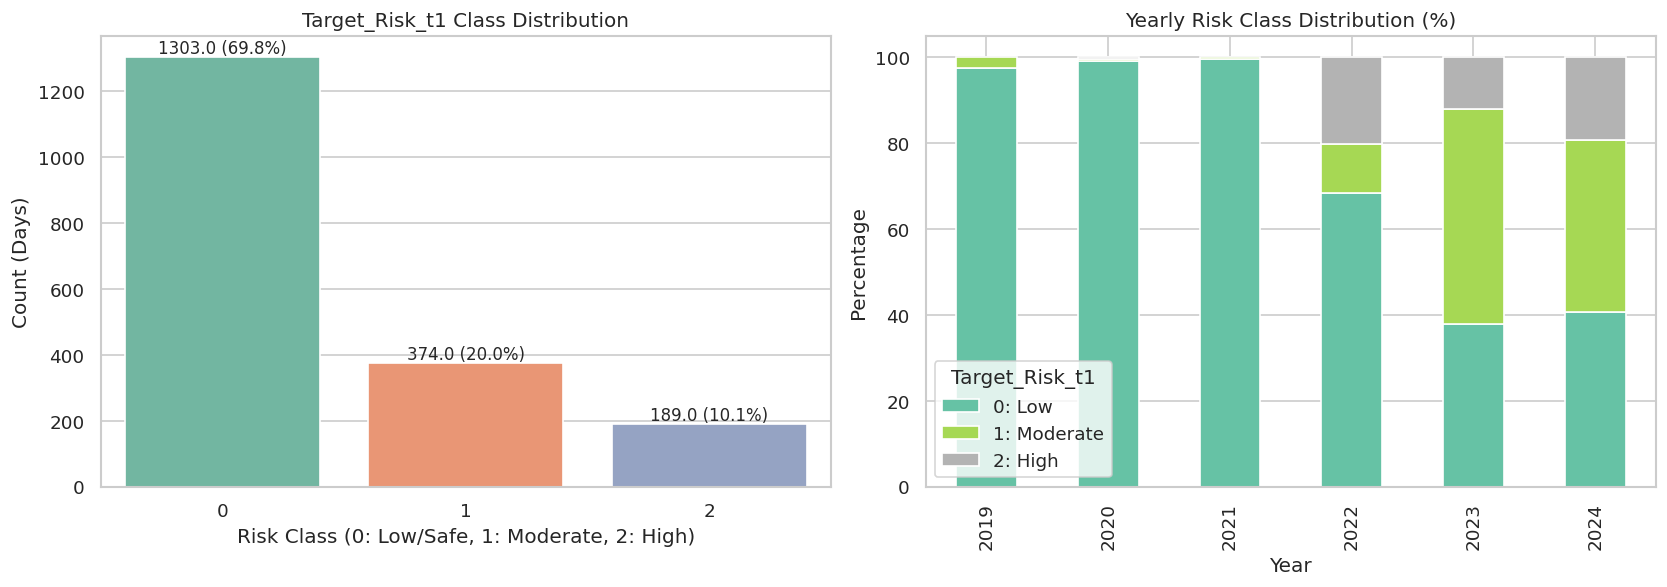

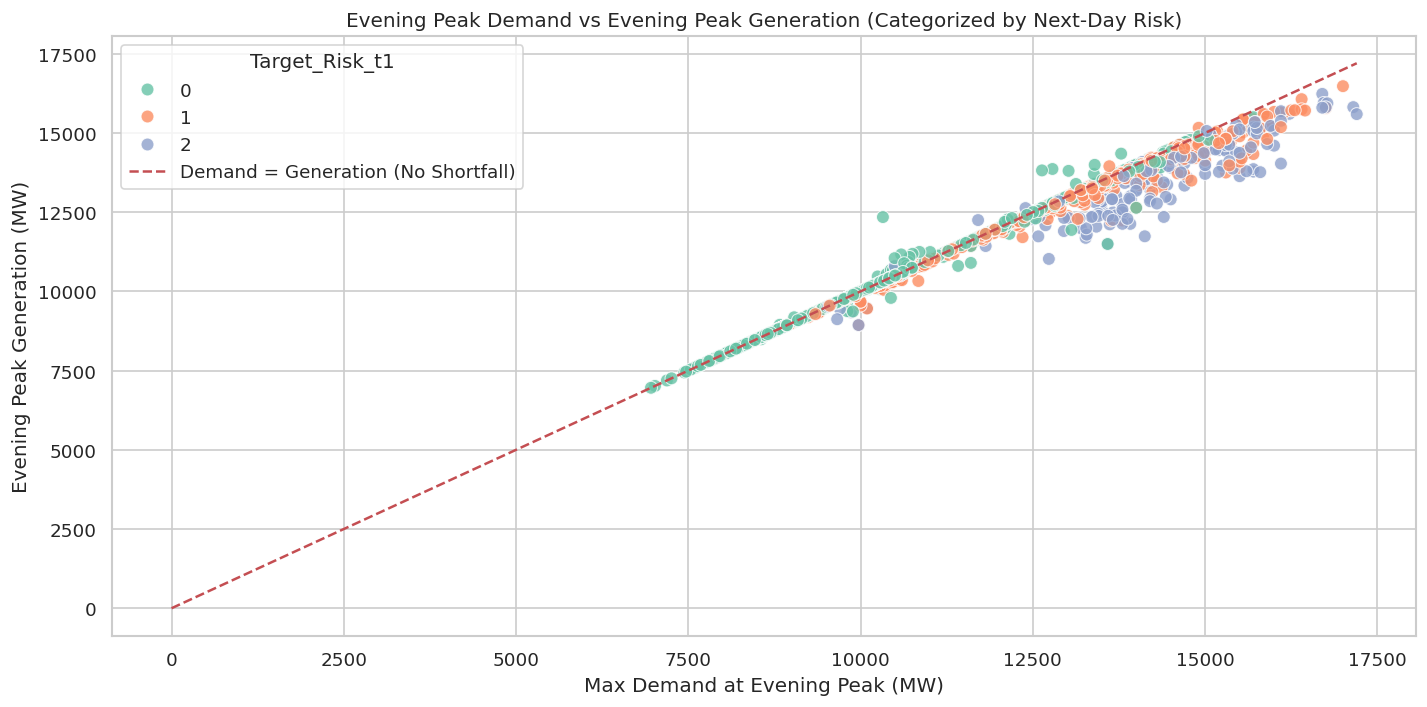

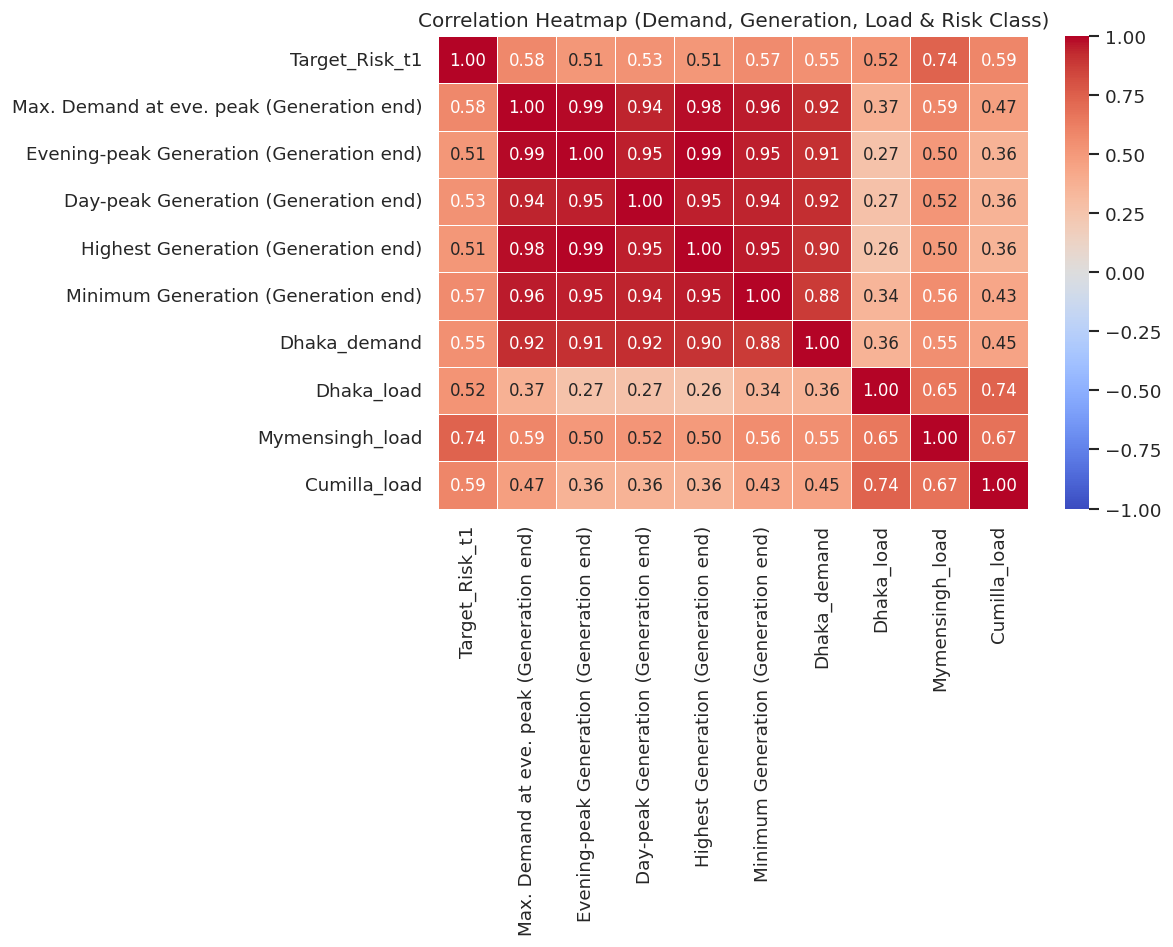

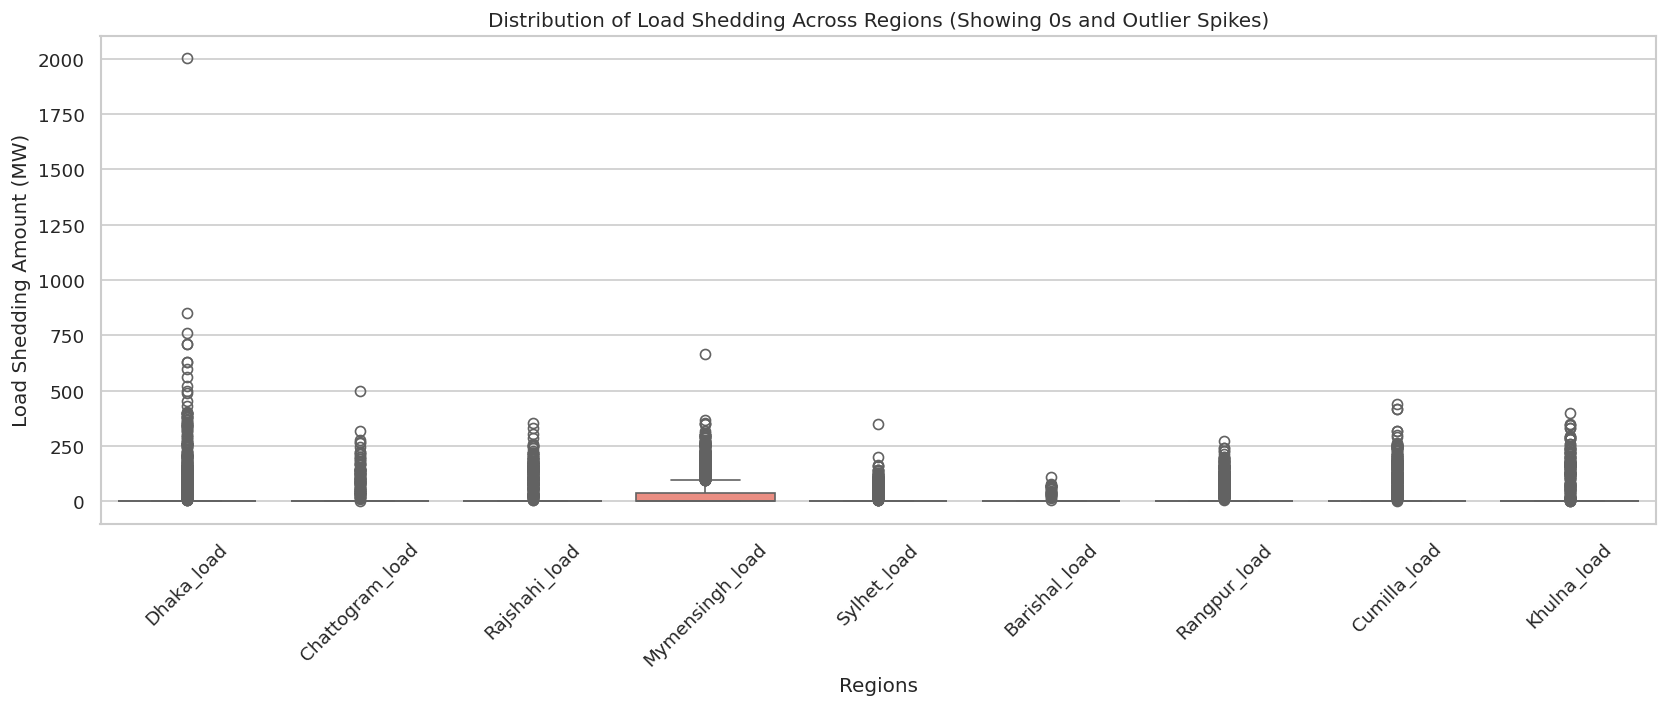

All 4 EDA plots successfully saved to save_dir (/kaggle/working/)!


In [28]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean Dataset Load
df_clean = pd.read_csv('/kaggle/working/Grid_Risk_Clean_Dataset.csv')

# Save Directory Definition
save_dir = '/kaggle/working/'
os.makedirs(save_dir, exist_ok=True)

# Plot Style Setup
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 10})

# ==========================================
# A. Target Class Distribution (Risk_t1)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count Plot
sns.countplot(data=df_clean, x='Target_Risk_t1', palette='Set2', ax=axes[0])
axes[0].set_title('Target_Risk_t1 Class Distribution')
axes[0].set_xlabel('Risk Class (0: Low/Safe, 1: Moderate, 2: High)')
axes[0].set_ylabel('Count (Days)')

# Percentage Labels
total = len(df_clean)
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{height} ({height/total*100:.1f}%)', 
                     (p.get_x() + p.get_width() / 2., height), 
                     ha='center', va='bottom', fontsize=10)

# Target vs Year Trend (Stacked Bar)
risk_by_year = pd.crosstab(df_clean['Year'], df_clean['Target_Risk_t1'], normalize='index') * 100
risk_by_year.plot(kind='bar', stacked=True, colormap='Set2', ax=axes[1])
axes[1].set_title('Yearly Risk Class Distribution (%)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Percentage')
axes[1].legend(title='Target_Risk_t1', labels=['0: Low', '1: Moderate', '2: High'])

plt.tight_layout()
# Plot 1 Save
plt.savefig(os.path.join(save_dir, 'eda_target_risk_distribution.png'), bbox_inches='tight')
plt.show()

# ==========================================
# B. Peak Demand vs Generation & Risk Comparison
# ==========================================
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_clean, 
    x='Max. Demand at eve. peak (Generation end)', 
    y='Evening-peak Generation (Generation end)', 
    hue='Target_Risk_t1', 
    palette='Set2', 
    alpha=0.8,
    s=60
)

# 1:1 Equality Reference Line
max_val = max(df_clean['Max. Demand at eve. peak (Generation end)'].max(), 
              df_clean['Evening-peak Generation (Generation end)'].max())
plt.plot([0, max_val], [0, max_val], 'r--', label='Demand = Generation (No Shortfall)')

plt.title('Evening Peak Demand vs Evening Peak Generation (Categorized by Next-Day Risk)')
plt.xlabel('Max Demand at Evening Peak (MW)')
plt.ylabel('Evening Peak Generation (MW)')
plt.legend(title='Target_Risk_t1')
plt.tight_layout()
# Plot 2 Save
plt.savefig(os.path.join(save_dir, 'eda_demand_vs_generation.png'), bbox_inches='tight')
plt.show()

# ==========================================
# C. Correlation Heatmap (Key Features)
# ==========================================
plt.figure(figsize=(10, 8))

corr_cols = [
    'Target_Risk_t1', 
    'Max. Demand at eve. peak (Generation end)',
    'Evening-peak Generation (Generation end)',
    'Day-peak Generation (Generation end)',
    'Highest Generation (Generation end)',
    'Minimum Generation (Generation end)',
    'Dhaka_demand', 'Dhaka_load',
    'Mymensingh_load', 'Cumilla_load'
]

corr_matrix = df_clean[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap (Demand, Generation, Load & Risk Class)')
plt.tight_layout()
# Plot 3 Save
plt.savefig(os.path.join(save_dir, 'eda_correlation_heatmap.png'), bbox_inches='tight')
plt.show()

# ==========================================
# D. Regional Load Shedding (Load) Box Plot Analysis
# ==========================================
load_cols = [col for col in df_clean.columns if '_load' in col]

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_clean[load_cols], palette='Set3')
plt.xticks(rotation=45)
plt.title('Distribution of Load Shedding Across Regions (Showing 0s and Outlier Spikes)')
plt.ylabel('Load Shedding Amount (MW)')
plt.xlabel('Regions')
plt.tight_layout()
# Plot 4 Save
plt.savefig(os.path.join(save_dir, 'eda_regional_load_shedding_boxplot.png'), bbox_inches='tight')
plt.show()

print("All 4 EDA plots successfully saved to save_dir (/kaggle/working/)!")

In [29]:
plt.savefig(os.path.join(save_dir, 'eda_regional_load_shedding_boxplot.png'), bbox_inches='tight')

<Figure size 768x576 with 0 Axes>

## Train Test Split 

In [30]:
# =========================================================
# Stratified Train-Test Split, Scaling & Google Drive Save
# =========================================================
import os
import pickle
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from google.colab import drive

# 1. Google Drive Mount
#drive.mount('/content/drive')

save_dir = '/kaggle/working/'
os.makedirs(save_dir, exist_ok=True)

# 2. Split X & y
X = df_final.drop(columns=['Target_Risk_t1'])
y = df_final['Target_Risk_t1']

# 3. Stratified Random Split (80% Train, 20% Test)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Standard Scaling (Train> Fit, Test>only Transform)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns)

# Full Scaled Dataset (For Overall deployment / analysis)
X_scaled_all = pd.DataFrame(scaler.transform(X), columns=X.columns)
df_scaled_final = X_scaled_all.copy()
df_scaled_final['Target_Risk_t1'] = y.values

# 5. Scaled Files & Objects Save (Drive File Overwrite / Replace)
# (a) Full Scaled Dataset (CSV)
df_scaled_final.to_csv(os.path.join(save_dir, 'Grid_Risk_Scaled_Dataset.csv'), index=False)

# (b) Stratified Train & Test Sets Separately (CSV)
X_train_scaled.to_csv(os.path.join(save_dir, 'X_train_stratified.csv'), index=False)
X_test_scaled.to_csv(os.path.join(save_dir, 'X_test_stratified.csv'), index=False)
y_train.to_csv(os.path.join(save_dir, 'y_train_stratified.csv'), index=False)
y_test.to_csv(os.path.join(save_dir, 'y_test_stratified.csv'), index=False)

# (c) Save Scaler Object (.pkl)
with open(os.path.join(save_dir, 'scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)

print("Stratified Scaled Datasets & Scaler Object successfully updated and saved !")
print(f"Stratified Train Shape: {X_train_scaled.shape}, Test Shape: {X_test_scaled.shape}")

Stratified Scaled Datasets & Scaler Object successfully updated and saved !
Stratified Train Shape: (1492, 48), Test Shape: (374, 48)


## Load Scaled Data for Model Training

In [31]:
import pandas as pd
import pickle

# Stratified Pre-Scaled Train & Test Load (Updated File Names)
X_train = pd.read_csv('/kaggle/working/X_train_stratified.csv')
X_test = pd.read_csv('/kaggle/working/X_test_stratified.csv')
y_train = pd.read_csv('/kaggle/working/y_train_stratified.csv').values.ravel()
y_test = pd.read_csv('/kaggle/working/y_test_stratified.csv').values.ravel()

# Scaler Load
with open('/kaggle/working//scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

print("Stratified Datasets & Scaler Loaded Successfully!")
print(f"X_train Shape: {X_train.shape}, X_test Shape: {X_test.shape}")
print("Ready for Machine Learning Training!")

Stratified Datasets & Scaler Loaded Successfully!
X_train Shape: (1492, 48), X_test Shape: (374, 48)
Ready for Machine Learning Training!


In [32]:
X_train.head(3)

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code
0,-0.625073,-0.460613,-1.389260,-1.369630,-1.218443,-0.877439,-1.216015,-1.431374,-0.581849,1.123290,...,-0.610106,-0.589216,-0.24661,2.035139,-0.073912,-0.475000,-0.518844,1.566430,-1.487426,-2.567648
1,-0.625073,-0.460613,0.619765,0.554557,0.724822,0.837253,0.770588,0.733708,0.712780,0.927086,...,0.676732,0.744408,-0.24661,-0.379515,1.643789,-0.334370,-0.387671,-0.638394,-0.990618,0.145903
2,0.745404,0.687169,1.454166,1.440054,1.549484,1.198013,1.355635,1.572499,1.427188,0.215847,...,1.340431,1.432237,-0.24661,-0.379515,1.185736,0.781294,0.792882,-0.638394,0.002997,0.145903


In [33]:
X_train.shape

(1492, 48)

In [34]:
X_test.head(3)

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code
0,-1.310312,-0.747559,-0.818579,-0.837356,-0.831117,-1.187818,-1.288013,-0.816364,-0.723691,0.828984,...,0.031470,0.075685,-0.24661,-0.379515,-0.302939,-0.765635,-0.715602,-0.638394,-0.493811,0.145903
1,-0.625073,0.113278,0.600283,0.564315,0.692672,0.634476,0.705523,0.712713,0.581899,0.779933,...,0.886904,0.962220,-0.24661,-0.379515,0.269628,0.125021,0.071433,-0.638394,-0.990618,0.145903
2,-0.625073,0.400224,0.571773,0.470642,0.662053,0.696610,0.523662,0.681988,0.584734,0.289424,...,0.551367,0.614485,-0.24661,-0.379515,1.529276,0.518785,0.464950,-0.638394,-0.990618,0.145903


In [35]:
y_train

array([0, 0, 1, ..., 0, 0, 0])

In [36]:
y_test.shape

(374,)

In [37]:
y_train.shape

(1492,)

In [38]:
y_test

array([0, 0, 0, 0, 1, 1, 2, 0, 2, 0, 1, 1, 2, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       2, 1, 0, 0, 0, 0, 1, 1, 0, 0, 2, 0, 0, 1, 0, 1, 0, 0, 0, 2, 2, 2,
       0, 0, 0, 0, 0, 0, 2, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 2, 1, 0, 0,
       0, 0, 2, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 2, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 2, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 1, 0, 2, 0, 1, 0,
       0, 0, 0, 2, 0, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0,
       0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 2, 2, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 2, 0, 0, 0, 0, 0, 1, 2, 0, 0, 2, 1, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 0, 1, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 1, 0,
       0, 1, 1, 1, 0, 0, 0, 1, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 2, 0, 0,

In [39]:
X_train.head(3)

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,Day_of_month,Day_of_year,Week_of_year,Is_Weekend,Day_of_week_num,Holiday_name_code
0,-0.625073,-0.460613,-1.389260,-1.369630,-1.218443,-0.877439,-1.216015,-1.431374,-0.581849,1.123290,...,-0.610106,-0.589216,-0.24661,2.035139,-0.073912,-0.475000,-0.518844,1.566430,-1.487426,-2.567648
1,-0.625073,-0.460613,0.619765,0.554557,0.724822,0.837253,0.770588,0.733708,0.712780,0.927086,...,0.676732,0.744408,-0.24661,-0.379515,1.643789,-0.334370,-0.387671,-0.638394,-0.990618,0.145903
2,0.745404,0.687169,1.454166,1.440054,1.549484,1.198013,1.355635,1.572499,1.427188,0.215847,...,1.340431,1.432237,-0.24661,-0.379515,1.185736,0.781294,0.792882,-0.638394,0.002997,0.145903


## Feature Importance Check

     TOP 15 FEATURES (MI & ANOVA COMPARISON)      
                                             MI_Score  ANOVA_F_Score
Mymensingh_load                              0.362938     999.864366
Mymensingh_demand                            0.257818     501.452365
Year                                         0.250771     335.576877
Minimum Generation Forecast up to 8:00 hrs.  0.248581     412.617001
Max. Demand at eve. peak (Generation end)    0.239233     423.337234
Dhaka_load                                   0.239176     454.878985
Max. Demand at eve. peak (Sub-station end)   0.231109     407.318237
Cumilla_load                                 0.229240     477.086058
Dhaka_demand                                 0.224034     341.272950
Minimum Generation (Generation end)          0.223560     382.047435
Day-peak Generation (Generation end)         0.216589     368.826311
Rangpur_demand                               0.214575     289.713492
Sylhet_demand                                0.20226

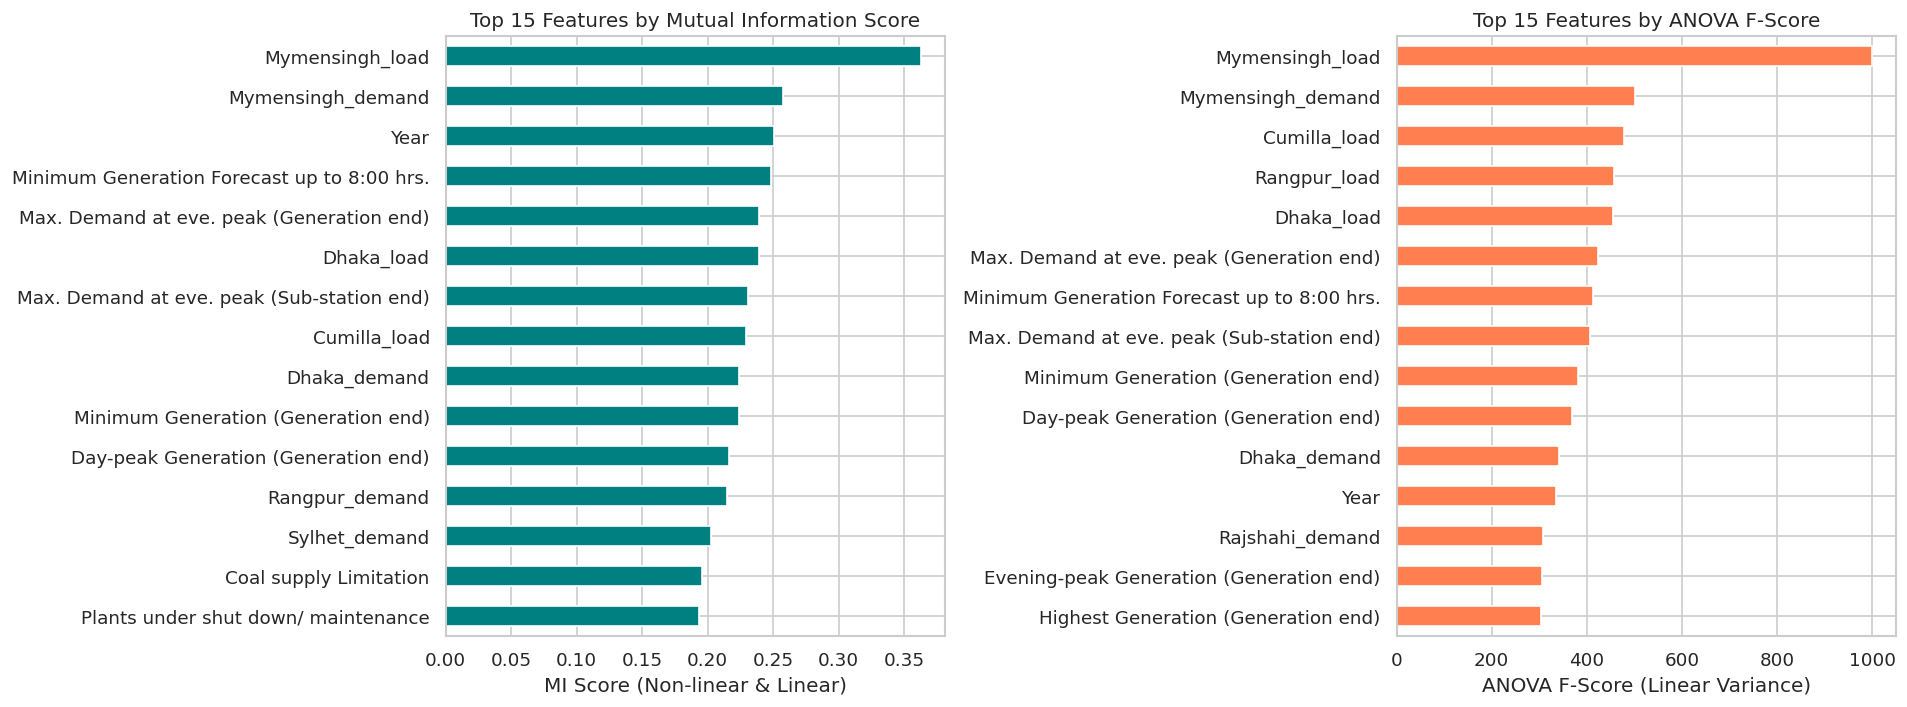

In [40]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, f_classif

# 1. Clean X_train from any zero-variance columns (Safety Check)
non_zero_var_cols = X_train.columns[X_train.var() > 0]
X_train_clean = X_train[non_zero_var_cols]

# 2. Calculate Mutual Information Score
mi_scores = mutual_info_classif(X_train_clean, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=X_train_clean.columns).sort_values(ascending=False)

# 3. Calculate ANOVA F-Score
f_scores, p_values = f_classif(X_train_clean, y_train)
# Replace potential NaNs with 0
f_scores = np.nan_to_num(f_scores)
f_series = pd.Series(f_scores, index=X_train_clean.columns).sort_values(ascending=False)

# 4. Display Combined DataFrame
importance_df = pd.DataFrame({
    'MI_Score': mi_series,
    'ANOVA_F_Score': f_series
}).sort_values(by='MI_Score', ascending=False)

print("==================================================")
print("     TOP 15 FEATURES (MI & ANOVA COMPARISON)      ")
print("==================================================")
print(importance_df.head(15))

# 5. Plot Side-by-Side Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# MI Plot
mi_series.head(15).plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title("Top 15 Features by Mutual Information Score")
axes[0].set_xlabel("MI Score (Non-linear & Linear)")
axes[0].invert_yaxis()

# ANOVA Plot
f_series.head(15).plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title("Top 15 Features by ANOVA F-Score")
axes[1].set_xlabel("ANOVA F-Score (Linear Variance)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## Base Models for just checking 

In [41]:
# 2. Base Random Forest Model (Default Parameters)
base_rf = RandomForestClassifier(random_state=42)
base_rf.fit(X_train, y_train)

# 3. Test Set Prediction
y_pred = base_rf.predict(X_test)

# 4. Baseline Results
print("==========================================")
print(f"Base Model Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Base Model F1-Macro : {f1_score(y_test, y_pred, average='macro'):.4f}")
print("==========================================")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Low Risk (0)', 'Moderate Risk (1)', 'High Risk (2)']))

Base Model Accuracy : 0.8422
Base Model F1-Macro : 0.7429

Classification Report:

                   precision    recall  f1-score   support

     Low Risk (0)       0.90      0.94      0.92       261
Moderate Risk (1)       0.68      0.57      0.62        75
    High Risk (2)       0.68      0.68      0.68        38

         accuracy                           0.84       374
        macro avg       0.76      0.73      0.74       374
     weighted avg       0.84      0.84      0.84       374



## Phase 1: Single-Output Multi-Model Baseline Benchmark Pipeline
This pipeline is structured into clean, modular blocks. Each model family is trained independently, and all predictions are aggregated at the end to display a detailed benchmark metrics table.

In [42]:
# ==============================================================================
# BLOCK 1: LIBRARIES, UTILITIES, AND DATA RESAMPLING (SMOTE)
# ==============================================================================
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# Classifiers
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Helper function for safe Multi-class / Binary ROC-AUC evaluation
def compute_roc_auc(y_true, y_prob):
    """
    Computes One-vs-Rest (OvR) Macro ROC-AUC score safely.
    Handles potential issues when predicted class probabilities are missing.
    """
    if y_prob is None:
        return np.nan
    try:
        prob_arr = np.asarray(y_prob)
        n_classes = len(np.unique(y_true))
        if n_classes == 2:
            return roc_auc_score(y_true, prob_arr[:, 1])
        else:
            return roc_auc_score(y_true, prob_arr, multi_class='ovr', average='macro')
    except Exception:
        return np.nan

# Global Dictionary to store all model predictions & probabilities
model_predictions = {}
model_probabilities = {}

# Apply SMOTE resampling on single-output training set
smote = SMOTE(random_state=42)
X_tr_resampled, y_tr_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"SMOTE applied successfully.")
print(f"Original Train Samples: {len(X_train_scaled)} | Resampled Train Samples: {len(X_tr_resampled)}\n")

SMOTE applied successfully.
Original Train Samples: 1492 | Resampled Train Samples: 3126



## Phase-1.1: Tree based Ensembled Models (Random Forest Classifier, Extra Trees, Gradient Boosting)

In [43]:
# ==============================================================================
# BLOCK 2: TREE-BASED ENSEMBLE MODELS (RF, EXTRA TREES, GRADIENT BOOSTING)
# ==============================================================================
print("Training Tree-based Ensemble Models...")

# 1. Random Forest
rf = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
rf.fit(X_tr_resampled, y_tr_resampled)
model_predictions['Random Forest'] = rf.predict(X_test_scaled)
model_probabilities['Random Forest'] = rf.predict_proba(X_test_scaled)

# 2. Extra Trees
et = ExtraTreesClassifier(n_estimators=150, random_state=42, n_jobs=-1)
et.fit(X_tr_resampled, y_tr_resampled)
model_predictions['Extra Trees'] = et.predict(X_test_scaled)
model_probabilities['Extra Trees'] = et.predict_proba(X_test_scaled)

# 3. Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, random_state=42)
gb.fit(X_tr_resampled, y_tr_resampled)
model_predictions['Gradient Boosting'] = gb.predict(X_test_scaled)
model_probabilities['Gradient Boosting'] = gb.predict_proba(X_test_scaled)

print("Tree-based ensemble models training completed.\n")

Training Tree-based Ensemble Models...
Tree-based ensemble models training completed.



## Phase-1.2: MODERN GRADIENT BOOSTING FRAMEWORKS (LIGHTGBM, XGBOOST, CATBOOST)

In [44]:
# ==============================================================================
# BLOCK 3: MODERN GRADIENT BOOSTING FRAMEWORKS (LIGHTGBM, XGBOOST, CATBOOST)
# ==============================================================================
import re
print("Training Modern Gradient Boosting Frameworks...")

# Sanitize feature names to remove special JSON characters for LightGBM compatibility
def sanitize_column_names(df):
    clean_cols = []
    for col in df.columns:
        clean_col = re.sub(r'[\s,.:;"\'()|[\\\]{}<>/\\-]', '_', str(col))
        clean_cols.append(clean_col)
    df_cleaned = df.copy()
    df_cleaned.columns = clean_cols
    return df_cleaned

X_tr_resampled_clean = sanitize_column_names(X_tr_resampled)
X_test_scaled_clean = sanitize_column_names(X_test_scaled)

# 1. LightGBM
lgb = LGBMClassifier(n_estimators=150, learning_rate=0.05, random_state=42, verbose=-1, n_jobs=-1)
lgb.fit(X_tr_resampled_clean, y_tr_resampled)
model_predictions['LightGBM'] = lgb.predict(X_test_scaled_clean)
model_probabilities['LightGBM'] = lgb.predict_proba(X_test_scaled_clean)

# 2. XGBoost
xgb = XGBClassifier(n_estimators=150, learning_rate=0.05, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb.fit(X_tr_resampled_clean, y_tr_resampled)
model_predictions['XGBoost'] = xgb.predict(X_test_scaled_clean)
model_probabilities['XGBoost'] = xgb.predict_proba(X_test_scaled_clean)

# 3. CatBoost
cb = CatBoostClassifier(iterations=150, learning_rate=0.05, random_state=42, verbose=0)
cb.fit(X_tr_resampled_clean, y_tr_resampled)
model_predictions['CatBoost'] = cb.predict(X_test_scaled_clean)
model_probabilities['CatBoost'] = cb.predict_proba(X_test_scaled_clean)

print("Gradient boosting frameworks training completed with sanitized feature names.\n")

Training Modern Gradient Boosting Frameworks...
Gradient boosting frameworks training completed with sanitized feature names.



## Phase-1.3: LINEAR & DISTANCE-BASED MODELS (LOGISTIC REGRESSION, SVM)

In [45]:
# ==============================================================================
# BLOCK 4: LINEAR & DISTANCE-BASED MODELS (LOGISTIC REGRESSION, SVM)
# ==============================================================================
print("Training Linear and Distance-based Models...")

# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_tr_resampled, y_tr_resampled)
model_predictions['Logistic Regression'] = lr.predict(X_test_scaled)
model_probabilities['Logistic Regression'] = lr.predict_proba(X_test_scaled)

# 2. Support Vector Machine (SVM)
svm = SVC(probability=True, random_state=42)
svm.fit(X_tr_resampled, y_tr_resampled)
model_predictions['Support Vector Machine'] = svm.predict(X_test_scaled)
model_probabilities['Support Vector Machine'] = svm.predict_proba(X_test_scaled)

print("Linear and distance-based models training completed.\n")

Training Linear and Distance-based Models...
Linear and distance-based models training completed.



## Evaluation of Phase-1 Models

In [46]:
# ==============================================================================
# BLOCK 5: UNIFIED BENCHMARK EVALUATION & SUMMARY TABLE
# ==============================================================================
benchmark_results = []

for model_name in model_predictions.keys():
    y_pred = model_predictions[model_name]
    y_prob = model_probabilities[model_name]

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    precision_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
    auc_score = compute_roc_auc(y_test, y_prob)

    benchmark_results.append({
        'Model': model_name,
        'Accuracy': round(acc, 4),
        'F1-Macro': round(f1_macro, 4),
        'F1-Weighted': round(f1_weighted, 4),
        'Precision (Macro)': round(precision_macro, 4),
        'Recall (Macro)': round(recall_macro, 4),
        'ROC-AUC (Macro)': round(auc_score, 4) if not np.isnan(auc_score) else 'N/A'
    })

# Convert to DataFrame and sort by F1-Macro
df_benchmark = pd.DataFrame(benchmark_results).sort_values(by='F1-Macro', ascending=False).reset_index(drop=True)

print("\n" + "="*110)
print("SINGLE-OUTPUT BASELINE BENCHMARK EVALUATION TABLE")
print("="*110)
print(df_benchmark.to_string(index=False))


SINGLE-OUTPUT BASELINE BENCHMARK EVALUATION TABLE
                 Model  Accuracy  F1-Macro  F1-Weighted  Precision (Macro)  Recall (Macro)  ROC-AUC (Macro)
           Extra Trees    0.8503    0.7693       0.8496             0.7621          0.7798           0.9386
         Random Forest    0.8422    0.7621       0.8429             0.7539          0.7717           0.9349
              LightGBM    0.8476    0.7612       0.8463             0.7603          0.7636           0.9318
               XGBoost    0.8449    0.7548       0.8455             0.7491          0.7611           0.9343
              CatBoost    0.8369    0.7539       0.8401             0.7385          0.7723           0.9333
     Gradient Boosting    0.8369    0.7513       0.8393             0.7430          0.7605           0.9346
Support Vector Machine    0.8128    0.7277       0.8192             0.7037          0.7620           0.9125
   Logistic Regression    0.8021    0.7048       0.8077             0.6851          0

## Phase 2: K-Fold CV Hyperparametr Tuning + Complete Multi-Metric Scorecard Code

In [47]:
# ==============================================================================
# PREPARE SAFE ARRAYS FROM SMOTE RESAMPLED DATA
# ==============================================================================
!pip install -q optuna
import optuna
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

# Log level silent
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Ensure numpy arrays for safe StratifiedKFold indexing
X_cv = np.asarray(X_tr_resampled)
y_cv = np.asarray(y_tr_resampled)
X_test_eval = np.asarray(X_test_scaled)
y_test_eval = np.asarray(y_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_tuned_models = {}

print(f"Dataset Shape after SMOTE for CV: {X_cv.shape}")

Dataset Shape after SMOTE for CV: (3126, 48)


# Phase-2.1: Hyperparameter Tuning for Gradient Boost

In [48]:
# ==============================================================================
# 1. TUNING GRADIENT BOOSTING
# ==============================================================================
from sklearn.ensemble import GradientBoostingClassifier

def objective_gbm(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'random_state': 42
    }

    cv_f1 = []
    for train_idx, val_idx in cv.split(X_cv, y_cv):
        X_tr, X_val = X_cv[train_idx], X_cv[val_idx]
        y_tr, y_val = y_cv[train_idx], y_cv[val_idx]

        clf = GradientBoostingClassifier(**params)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_val)
        cv_f1.append(f1_score(y_val, preds, average='macro', zero_division=0))

    return np.mean(cv_f1)

print("Tuning Gradient Boosting with 5-Fold CV...")
study_gbm = optuna.create_study(direction='maximize')
study_gbm.optimize(objective_gbm, n_trials=15, show_progress_bar=True)

best_gbm = GradientBoostingClassifier(**study_gbm.best_params, random_state=42)
best_gbm.fit(X_cv, y_cv)
best_tuned_models['Gradient Boosting'] = best_gbm

Tuning Gradient Boosting with 5-Fold CV...


  0%|          | 0/15 [00:00<?, ?it/s]

## Phase-2.2: Hyperparameter Tuning for XGBOOST

In [49]:
# ==============================================================================
# 2. TUNING XGBOOST
# ==============================================================================
from xgboost import XGBClassifier

def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'n_jobs': -1,
        'eval_metric': 'mlogloss'
    }

    cv_f1 = []
    for train_idx, val_idx in cv.split(X_cv, y_cv):
        X_tr, X_val = X_cv[train_idx], X_cv[val_idx]
        y_tr, y_val = y_cv[train_idx], y_cv[val_idx]

        clf = XGBClassifier(**params)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_val)
        cv_f1.append(f1_score(y_val, preds, average='macro', zero_division=0))

    return np.mean(cv_f1)

print("Tuning XGBoost with 5-Fold CV...")
study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(objective_xgb, n_trials=15, show_progress_bar=True)

best_xgb = XGBClassifier(**study_xgb.best_params, random_state=42, n_jobs=-1, eval_metric='mlogloss')
best_xgb.fit(X_cv, y_cv)
best_tuned_models['XGBoost'] = best_xgb

Tuning XGBoost with 5-Fold CV...


  0%|          | 0/15 [00:00<?, ?it/s]

In [50]:
# ==============================================================================
# 3. TUNING LIGHTGBM
# ==============================================================================
from lightgbm import LGBMClassifier

def objective_lgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 127),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1
    }

    cv_f1 = []
    for train_idx, val_idx in cv.split(X_cv, y_cv):
        X_tr, X_val = X_cv[train_idx], X_cv[val_idx]
        y_tr, y_val = y_cv[train_idx], y_cv[val_idx]

        clf = LGBMClassifier(**params)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_val)
        cv_f1.append(f1_score(y_val, preds, average='macro', zero_division=0))

    return np.mean(cv_f1)

print("Tuning LightGBM with 5-Fold CV...")
study_lgb = optuna.create_study(direction='maximize')
study_lgb.optimize(objective_lgb, n_trials=30, show_progress_bar=True)

best_lgb = LGBMClassifier(**study_lgb.best_params, random_state=42, verbose=-1, n_jobs=-1)
best_lgb.fit(X_cv, y_cv)
best_tuned_models['LightGBM'] = best_lgb

Tuning LightGBM with 5-Fold CV...


  0%|          | 0/30 [00:00<?, ?it/s]

In [51]:
# ==============================================================================
# 4. TUNING CATBOOST
# ==============================================================================
from catboost import CatBoostClassifier

def objective_cb(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 300, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'depth': trial.suggest_int('depth', 4, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'random_state': 42,
        'verbose': 0
    }

    cv_f1 = []
    for train_idx, val_idx in cv.split(X_cv, y_cv):
        X_tr, X_val = X_cv[train_idx], X_cv[val_idx]
        y_tr, y_val = y_cv[train_idx], y_cv[val_idx]

        clf = CatBoostClassifier(**params)
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_val)
        cv_f1.append(f1_score(y_val, preds, average='macro', zero_division=0))

    return np.mean(cv_f1)

print("Tuning CatBoost with 5-Fold CV...")
study_cb = optuna.create_study(direction='maximize')
study_cb.optimize(objective_cb, n_trials=15, show_progress_bar=True)

best_cb = CatBoostClassifier(**study_cb.best_params, random_state=42, verbose=0)
best_cb.fit(X_cv, y_cv)
best_tuned_models['CatBoost'] = best_cb

Tuning CatBoost with 5-Fold CV...


  0%|          | 0/15 [00:00<?, ?it/s]

# Hyper Parameter Tuning for Extra Trees and Random Forest

In [52]:
import os
import pickle
import optuna
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

save_dir = '/kaggle/working/'
os.makedirs(save_dir, exist_ok=True)

optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==========================================
# 1. Optuna Tuning: Extra Trees Classifier
# ==========================================
print("Tuning Extra Trees Classifier...")

def objective_et(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 5, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'random_state': 42,
        'n_jobs': -1
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    model = ExtraTreesClassifier(**params)
    
    # Corrected variable name: X_tr_resampled & y_tr_resampled
    score = cross_val_score(model, X_tr_resampled, y_tr_resampled, cv=cv, scoring='f1_macro').mean()
    return score

study_et = optuna.create_study(direction='maximize')
study_et.optimize(objective_et, n_trials=30)

# Fit Tuned Extra Trees
best_et_model = ExtraTreesClassifier(**study_et.best_params, random_state=42, n_jobs=-1)
best_et_model.fit(X_tr_resampled, y_tr_resampled)

# ==========================================
# 2. Optuna Tuning: Random Forest Classifier
# ==========================================
print("Tuning Random Forest Classifier...")

def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 5, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
        'random_state': 42,
        'n_jobs': -1
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    model = RandomForestClassifier(**params)
    
    # Corrected variable name: X_tr_resampled & y_tr_resampled
    score = cross_val_score(model, X_tr_resampled, y_tr_resampled, cv=cv, scoring='f1_macro').mean()
    return score

study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(objective_rf, n_trials=30)

# Fit Tuned Random Forest
best_rf_model = RandomForestClassifier(**study_rf.best_params, random_state=42, n_jobs=-1)
best_rf_model.fit(X_tr_resampled, y_tr_resampled)

# ==========================================
# 3. Save Tuned Models as .pkl Files
# ==========================================
with open(os.path.join(save_dir, 'tuned_extra_trees.pkl'), 'wb') as f:
    pickle.dump(best_et_model, f)

with open(os.path.join(save_dir, 'tuned_random_forest.pkl'), 'wb') as f:
    pickle.dump(best_rf_model, f)

print("Tuning complete and models saved to /kaggle/working/!")

Tuning Extra Trees Classifier...
Tuning Random Forest Classifier...
Tuning complete and models saved to /kaggle/working/!


## Save Tuned Models 

In [53]:
import joblib
import os

# Path definition
drive_save_path = '/kaggle/working/'
os.makedirs(drive_save_path, exist_ok=True)

# 1. Best Tuned Base Models Save (All 6 Models)
joblib.dump(best_gbm, os.path.join(drive_save_path, 'best_gbm.pkl'))
joblib.dump(best_cb, os.path.join(drive_save_path, 'best_catboost.pkl'))
joblib.dump(best_lgb, os.path.join(drive_save_path, 'best_lightgbm.pkl'))
joblib.dump(best_xgb, os.path.join(drive_save_path, 'best_xgboost.pkl'))
joblib.dump(best_et_model, os.path.join(drive_save_path, 'best_extra_trees.pkl'))
joblib.dump(best_rf_model, os.path.join(drive_save_path, 'best_random_forest.pkl'))

# 2. Scaler Save 
joblib.dump(scaler, os.path.join(drive_save_path, 'scaler.pkl'))

print(f"All 6 tuned base models and scaler successfully saved to '{drive_save_path}'!")

All 6 tuned base models and scaler successfully saved to '/kaggle/working/'!


## Evaluation of Tunned Models

In [54]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# ==============================================================================
# 1. LOAD ALL TUNED MODELS & SCALER FROM DISK
# ==============================================================================
drive_save_path = '/kaggle/working/'

loaded_models = {
    'Extra Trees (Tuned)': joblib.load(os.path.join(drive_save_path, 'best_extra_trees.pkl')),
    'Random Forest (Tuned)': joblib.load(os.path.join(drive_save_path, 'best_random_forest.pkl')),
    'LightGBM (Tuned)': joblib.load(os.path.join(drive_save_path, 'best_lightgbm.pkl')),
    'XGBoost (Tuned)': joblib.load(os.path.join(drive_save_path, 'best_xgboost.pkl')),
    'CatBoost (Tuned)': joblib.load(os.path.join(drive_save_path, 'best_catboost.pkl')),
    'Gradient Boosting (Tuned)': joblib.load(os.path.join(drive_save_path, 'best_gbm.pkl'))
}

scaler = joblib.load(os.path.join(drive_save_path, 'scaler.pkl'))
print("All tuned models and scaler successfully loaded from disk!")

# ==============================================================================
# 2. MULTI-METRIC EVALUATION ON TEST SET
# ==============================================================================
# Test Data setup
X_eval = X_test_scaled if 'X_test_scaled' in locals() else X_test
y_eval = y_test

tuned_metrics_results = []

for model_name, model in loaded_models.items():
    y_pred = model.predict(X_eval)

    # ROC-AUC (Macro) Evaluation
    try:
        y_prob = model.predict_proba(X_eval)
        auc_score = roc_auc_score(y_eval, y_prob, multi_class='ovr', average='macro')
    except Exception:
        auc_score = np.nan

    acc = accuracy_score(y_eval, y_pred)
    f1_macro = f1_score(y_eval, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_eval, y_pred, average='weighted', zero_division=0)
    precision_macro = precision_score(y_eval, y_pred, average='macro', zero_division=0)
    recall_macro = recall_score(y_eval, y_pred, average='macro', zero_division=0)

    tuned_metrics_results.append({
        'Model (Tuned)': model_name,
        'Accuracy': round(acc, 4),
        'F1-Macro': round(f1_macro, 4),
        'F1-Weighted': round(f1_weighted, 4),
        'Precision (Macro)': round(precision_macro, 4),
        'Recall (Macro)': round(recall_macro, 4),
        'ROC-AUC (Macro)': round(auc_score, 4) if not np.isnan(auc_score) else 'N/A'
    })

# DataFrame Construction & Sorting by F1-Macro
df_tuned_comparison = pd.DataFrame(tuned_metrics_results).sort_values(by='F1-Macro', ascending=False).reset_index(drop=True)

print("\n" + "="*100)
print("PHASE 2: TUNED MODELS MULTI-METRIC COMPARISON TABLE")
print("="*100)
print(df_tuned_comparison.to_string(index=False))

All tuned models and scaler successfully loaded from disk!

PHASE 2: TUNED MODELS MULTI-METRIC COMPARISON TABLE
            Model (Tuned)  Accuracy  F1-Macro  F1-Weighted  Precision (Macro)  Recall (Macro)  ROC-AUC (Macro)
      Extra Trees (Tuned)    0.8529    0.7721       0.8538             0.7604          0.7874           0.9385
          XGBoost (Tuned)    0.8503    0.7663       0.8501             0.7623          0.7712           0.9343
    Random Forest (Tuned)    0.8449    0.7634       0.8442             0.7560          0.7741           0.9383
         CatBoost (Tuned)    0.8396    0.7568       0.8411             0.7484          0.7661           0.9308
         LightGBM (Tuned)    0.8476    0.7554       0.8464             0.7556          0.7561           0.9349
Gradient Boosting (Tuned)    0.8449    0.7513       0.8445             0.7522          0.7505           0.9342


## Stacking of best models




In [55]:
import re

# 1. Feature Clean function
def clean_feature_names(df):
    # Regex test to rename special JSON symbols and spaces to underscores
    return df.rename(columns=lambda x: re.sub(r'[^\w\s]', '', x).replace(' ', '_'))

# 2. Rename columns in X, X_tr_resampled, and X_test_scaled
if 'X' in locals():
    X = clean_feature_names(X)

if 'X_tr_resampled' in locals():
    if isinstance(X_tr_resampled, pd.DataFrame):
        X_tr_resampled = clean_feature_names(X_tr_resampled)

if 'X_test_scaled' in locals():
    if isinstance(X_test_scaled, pd.DataFrame):
        X_test_scaled = clean_feature_names(X_test_scaled)

Loading tuned base models...
Training Stacking Ensemble Classifier...
Stacking model successfully trained and saved!

STACKING ENSEMBLE PERFORMANCE METRICS
                        Model  Accuracy  F1-Macro  F1-Weighted  Precision (Macro)  Recall (Macro)  ROC-AUC (Macro)
Stacking Ensemble (Optimized)    0.8476    0.7568       0.8462             0.7621          0.7517           0.9259


<Figure size 840x720 with 0 Axes>

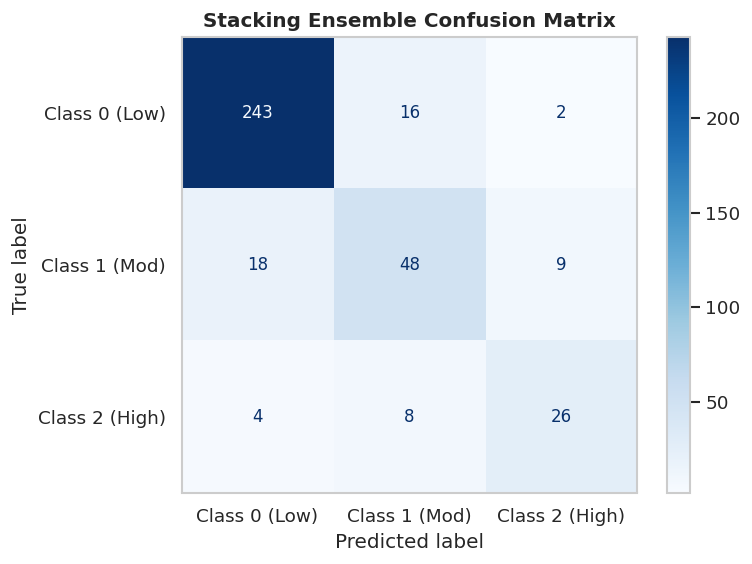

Evaluation completed and confusion matrix saved to /kaggle/working/!


In [56]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, 
    recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

# Set save directory
save_dir = '/kaggle/working/'

# ==============================================================================
# 1. LOAD ALL TUNED BASE MODELS & SCALER FROM DISK
# ==============================================================================
print("Loading tuned base models...")

tuned_cb = joblib.load(os.path.join(save_dir, 'best_catboost.pkl'))
tuned_xgb = joblib.load(os.path.join(save_dir, 'best_xgboost.pkl'))
tuned_lgb = joblib.load(os.path.join(save_dir, 'best_lightgbm.pkl'))
tuned_et  = joblib.load(os.path.join(save_dir, 'best_extra_trees.pkl'))
tuned_rf  = joblib.load(os.path.join(save_dir, 'best_random_forest.pkl'))
tuned_gbm = joblib.load(os.path.join(save_dir, 'best_gbm.pkl'))

# Define base estimators list for Stacking
estimators = [
    ('extra_trees', tuned_et),
    ('random_forest', tuned_rf),
    ('catboost', tuned_cb),
    ('xgboost', tuned_xgb),
    ('lightgbm', tuned_lgb),
    ('gbm', tuned_gbm)
]

# ==============================================================================
# 2. DEFINE & TRAIN STACKING ENSEMBLE CLASSIFIER
# ==============================================================================
print("Training Stacking Ensemble Classifier...")

# Meta-learner with L2 Regularization to avoid meta-overfitting
meta_learner = LogisticRegression(C=0.1, max_iter=1000, random_state=42)

stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_learner,
    passthrough=True,              # Passes original features + base predictions to meta-learner
    stack_method='predict_proba',  # Uses class probability outputs instead of hard labels
    cv=5,                          # 5-fold cross-validation for meta-feature generation
    n_jobs=-1
)

# Fit Stacking Model on SMOTE Training Data
stacking_model.fit(X_tr_resampled, y_tr_resampled)

# Save Trained Stacking Model
joblib.dump(stacking_model, os.path.join(save_dir, 'stacking_ensemble_model.pkl'))
print("Stacking model successfully trained and saved!")

# ==============================================================================
# 3. EVALUATION ON TEST SET
# ==============================================================================
X_eval = X_test_scaled if 'X_test_scaled' in locals() else X_test
y_eval = y_test

y_pred_stack = stacking_model.predict(X_eval)
y_prob_stack = stacking_model.predict_proba(X_eval)

acc = accuracy_score(y_eval, y_pred_stack)
f1_macro = f1_score(y_eval, y_pred_stack, average='macro', zero_division=0)
f1_weighted = f1_score(y_eval, y_pred_stack, average='weighted', zero_division=0)
prec_macro = precision_score(y_eval, y_pred_stack, average='macro', zero_division=0)
rec_macro = recall_score(y_eval, y_pred_stack, average='macro', zero_division=0)
auc_score = roc_auc_score(y_eval, y_prob_stack, multi_class='ovr', average='macro')

# Display Metrics Table
df_stacking_metrics = pd.DataFrame([{
    'Model': 'Stacking Ensemble (Optimized)',
    'Accuracy': round(acc, 4),
    'F1-Macro': round(f1_macro, 4),
    'F1-Weighted': round(f1_weighted, 4),
    'Precision (Macro)': round(prec_macro, 4),
    'Recall (Macro)': round(rec_macro, 4),
    'ROC-AUC (Macro)': round(auc_score, 4)
}])

print("\n" + "="*80)
print("STACKING ENSEMBLE PERFORMANCE METRICS")
print("="*80)
print(df_stacking_metrics.to_string(index=False))

# ==============================================================================
# 4. PLOT & SAVE CONFUSION MATRIX
# ==============================================================================
plt.figure(figsize=(7, 6))
cm = confusion_matrix(y_eval, y_pred_stack)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0 (Low)', 'Class 1 (Mod)', 'Class 2 (High)'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Stacking Ensemble Confusion Matrix', fontsize=12, fontweight='bold')
plt.grid(False)

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'stacking_confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

print("Evaluation completed and confusion matrix saved to /kaggle/working/!")

## Final Winner Stacking Model

Training Final Optimized Stacking Ensemble Classifier...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



MASTER MODEL PERFORMANCE COMPARISON TABLE (ALL STAGES)
               Stage                            Model  Accuracy  F1-Macro  F1-Weighted  Precision (Macro)  Recall (Macro)  ROC-AUC (Macro)
      2. Tuned Model                      Extra Trees    0.8529    0.7721       0.8538             0.7604          0.7874           0.9385
      2. Tuned Model                    Random Forest    0.8449    0.7634       0.8442             0.7560          0.7741           0.9383
      2. Tuned Model                         LightGBM    0.8476    0.7554       0.8464             0.7556          0.7561           0.9349
      2. Tuned Model                          XGBoost    0.8503    0.7663       0.8501             0.7623          0.7712           0.9343
      2. Tuned Model                         CatBoost    0.8396    0.7568       0.8411             0.7484          0.7661           0.9308
      2. Tuned Model                Gradient Boosting    0.8449    0.7513       0.8445             0.7522     

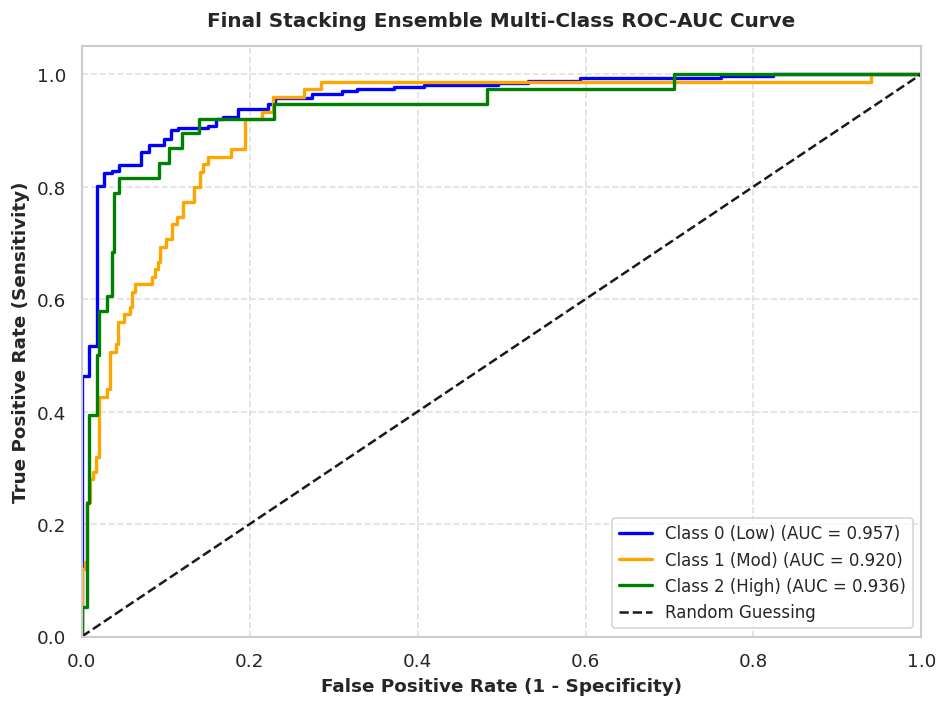

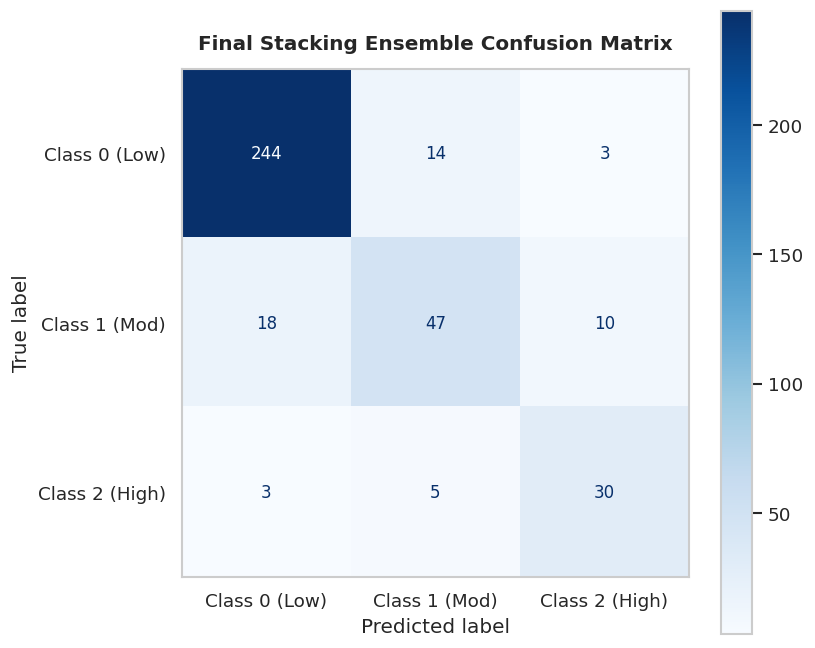


Saved Files in Directory ('/kaggle/working/'):
 1. Master_Model_Comparison_Table_v2.csv
 2. Final_Stacking_Ensemble_Metrics_v2.csv
 3. stacking_ensemble_model_final_v2.pkl
 4. final_stacking_roc_auc_curve_v2.png
 5. final_stacking_confusion_matrix_v2.png


In [57]:
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, 
    recall_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

save_dir = '/kaggle/working/'
os.makedirs(save_dir, exist_ok=True)

# 1. Dataset Preparation (Array Conversion for Error Prevention)
X_eval_raw = X_test_scaled if 'X_test_scaled' in locals() else X_test
X_eval_arr = X_eval_raw.values if isinstance(X_eval_raw, pd.DataFrame) else np.asarray(X_eval_raw)
y_eval = y_test.values if isinstance(y_test, (pd.Series, pd.DataFrame)) else np.asarray(y_test)

X_tr_arr = X_tr_resampled.values if isinstance(X_tr_resampled, pd.DataFrame) else np.asarray(X_tr_resampled)
y_tr_arr = y_tr_resampled.values if isinstance(y_tr_resampled, (pd.Series, pd.DataFrame)) else np.asarray(y_tr_resampled)

# 2. Final Stacking Model Training (Config 4: L1 Penalty, C=0.5)
print("Training Final Optimized Stacking Ensemble Classifier...")
meta_learner = LogisticRegression(penalty='l1', C=0.5, solver='liblinear', random_state=42)

final_stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_learner,
    passthrough=False,
    stack_method='predict_proba',
    cv=5,
    n_jobs=-1
)

final_stacking.fit(X_tr_arr, y_tr_arr)

# Save Stacking Model with Unique Name
joblib.dump(final_stacking, os.path.join(save_dir, 'stacking_ensemble_model_final_v2.pkl'))

# 3. Model Evaluation Metrics Calculation
y_pred_stack = final_stacking.predict(X_eval_arr)
y_prob_stack = final_stacking.predict_proba(X_eval_arr)

acc = accuracy_score(y_eval, y_pred_stack)
f1_m = f1_score(y_eval, y_pred_stack, average='macro', zero_division=0)
f1_w = f1_score(y_eval, y_pred_stack, average='weighted', zero_division=0)
prec_m = precision_score(y_eval, y_pred_stack, average='macro', zero_division=0)
rec_m = recall_score(y_eval, y_pred_stack, average='macro', zero_division=0)
auc_val = roc_auc_score(y_eval, y_prob_stack, multi_class='ovr', average='macro')

stack_metrics = {
    'Stage': '3. Proposed Ensemble',
    'Model': 'Stacking Ensemble (Optimized L1)',
    'Accuracy': round(acc, 4),
    'F1-Macro': round(f1_m, 4),
    'F1-Weighted': round(f1_w, 4),
    'Precision (Macro)': round(prec_m, 4),
    'Recall (Macro)': round(rec_m, 4),
    'ROC-AUC (Macro)': round(auc_val, 4)
}

df_stack_final = pd.DataFrame([stack_metrics])
df_stack_final.to_csv(os.path.join(save_dir, 'Final_Stacking_Ensemble_Metrics_v2.csv'), index=False)

# 4. Master Model Comparison Table Integration
def evaluate_model_performance(model, model_name, stage_name, X_arr, y):
    y_p = model.predict(X_arr)
    try:
        y_pr = model.predict_proba(X_arr)
        a_score = roc_auc_score(y, y_pr, multi_class='ovr', average='macro')
    except Exception:
        a_score = np.nan

    return {
        'Stage': stage_name,
        'Model': model_name,
        'Accuracy': round(accuracy_score(y, y_p), 4),
        'F1-Macro': round(f1_score(y, y_p, average='macro', zero_division=0), 4),
        'F1-Weighted': round(f1_score(y, y_p, average='weighted', zero_division=0), 4),
        'Precision (Macro)': round(precision_score(y, y_p, average='macro', zero_division=0), 4),
        'Recall (Macro)': round(recall_score(y, y_p, average='macro', zero_division=0), 4),
        'ROC-AUC (Macro)': round(a_score, 4) if not np.isnan(a_score) else 'N/A'
    }

all_results = []

if 'baseline_models' in locals() and isinstance(baseline_models, dict):
    for name, model in baseline_models.items():
        all_results.append(evaluate_model_performance(model, name, '1. Baseline (Untuned)', X_eval_arr, y_eval))

tuned_models_files = {
    'Extra Trees': 'best_extra_trees.pkl',
    'Random Forest': 'best_random_forest.pkl',
    'LightGBM': 'best_lightgbm.pkl',
    'XGBoost': 'best_xgboost.pkl',
    'CatBoost': 'best_catboost.pkl',
    'Gradient Boosting': 'best_gbm.pkl'
}

for name, filename in tuned_models_files.items():
    file_path = os.path.join(save_dir, filename)
    if os.path.exists(file_path):
        m = joblib.load(file_path)
        all_results.append(evaluate_model_performance(m, name, '2. Tuned Model', X_eval_arr, y_eval))

all_results.append(stack_metrics)

df_master = pd.DataFrame(all_results)
df_master.to_csv(os.path.join(save_dir, 'Master_Model_Comparison_Table_v2.csv'), index=False)

print("\n" + "="*110)
print("MASTER MODEL PERFORMANCE COMPARISON TABLE (ALL STAGES)")
print("="*110)
print(df_master.to_string(index=False))

# 5. Plot 1: Multi-Class ROC-AUC Curve
classes = [0, 1, 2]
y_eval_bin = label_binarize(y_eval, classes=classes)
class_names = ['Class 0 (Low)', 'Class 1 (Mod)', 'Class 2 (High)']

plt.figure(figsize=(8, 6))
colors = ['blue', 'orange', 'green']

for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_eval_bin[:, i], y_prob_stack[:, i])
    roc_auc_class = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2, label=f'{class_names[i]} (AUC = {roc_auc_class:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guessing')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11, fontweight='bold')
plt.title('Final Stacking Ensemble Multi-Class ROC-AUC Curve', fontsize=12, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

roc_fig_path = os.path.join(save_dir, 'final_stacking_roc_auc_curve_v2.png')
plt.tight_layout()
plt.savefig(roc_fig_path, dpi=300, bbox_inches='tight')
plt.show()

# 6. Plot 2: Confusion Matrix
cm = confusion_matrix(y_eval, y_pred_stack)
plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=class_names
)
disp.plot(cmap='Blues', values_format='d', ax=plt.gca())
plt.title('Final Stacking Ensemble Confusion Matrix', fontsize=12, fontweight='bold', pad=12)
plt.grid(False)

cm_fig_path = os.path.join(save_dir, 'final_stacking_confusion_matrix_v2.png')
plt.tight_layout()
plt.savefig(cm_fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nSaved Files in Directory ('{save_dir}'):")
print(" 1. Master_Model_Comparison_Table_v2.csv")
print(" 2. Final_Stacking_Ensemble_Metrics_v2.csv")
print(" 3. stacking_ensemble_model_final_v2.pkl")
print(" 4. final_stacking_roc_auc_curve_v2.png")
print(" 5. final_stacking_confusion_matrix_v2.png")

## Model testing

# Global SHAP Explanation on Stacking Ensemble

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1. Dataset Setup
X_eval_raw = X_test_scaled if 'X_test_scaled' in locals() else X_test
X_eval_df = pd.DataFrame(X_eval_raw, columns=X_train.columns) if not isinstance(X_eval_raw, pd.DataFrame) else X_eval_raw

# Background dataset sample for KernelExplainer to speed up computation
X_background = shap.sample(X_eval_df, 100, random_state=42)

# 2. KernelExplainer for Stacking Model (Predicting Class 2 Probabilities)
def stacking_predict_proba_class2(x):
    # Stacking ensemble's probability output for Class 2 (High Risk)
    return stacking_model.predict_proba(x)[:, 2]

explainer = shap.KernelExplainer(stacking_predict_proba_class2, X_background)

# Calculate SHAP values for evaluation set (using a subset of test set for fast execution)
X_test_sample = shap.sample(X_eval_df, min(200, len(X_eval_df)), random_state=42)
shap_values_stacking = explainer.shap_values(X_test_sample)

# 3. Global SHAP Beeswarm Summary Plot for Stacking Model
plt.figure(figsize=(10, 6), dpi=300)
shap.summary_plot(shap_values_stacking, X_test_sample, show=False)
plt.title("Stacking Ensemble - Global SHAP Impact (Class 2: High Risk)", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("stacking_shap_beeswarm.png", bbox_inches='tight', dpi=300)
plt.show()

# 4. Global SHAP Feature Importance Bar Plot
plt.figure(figsize=(10, 6), dpi=300)
shap.summary_plot(shap_values_stacking, X_test_sample, plot_type="bar", show=False)
plt.title("Stacking Ensemble - SHAP Feature Importance Ranking", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("stacking_shap_importance_bar.png", bbox_inches='tight', dpi=300)
plt.show()

print("\n[SUCCESS] Global Stacking SHAP plots saved as 'stacking_shap_beeswarm.png' and 'stacking_shap_importance_bar.png'")

  0%|          | 0/200 [00:00<?, ?it/s]

## Global SHAP Code (Multi-Class + Class 2 Focus

<Figure size 3000x1800 with 0 Axes>

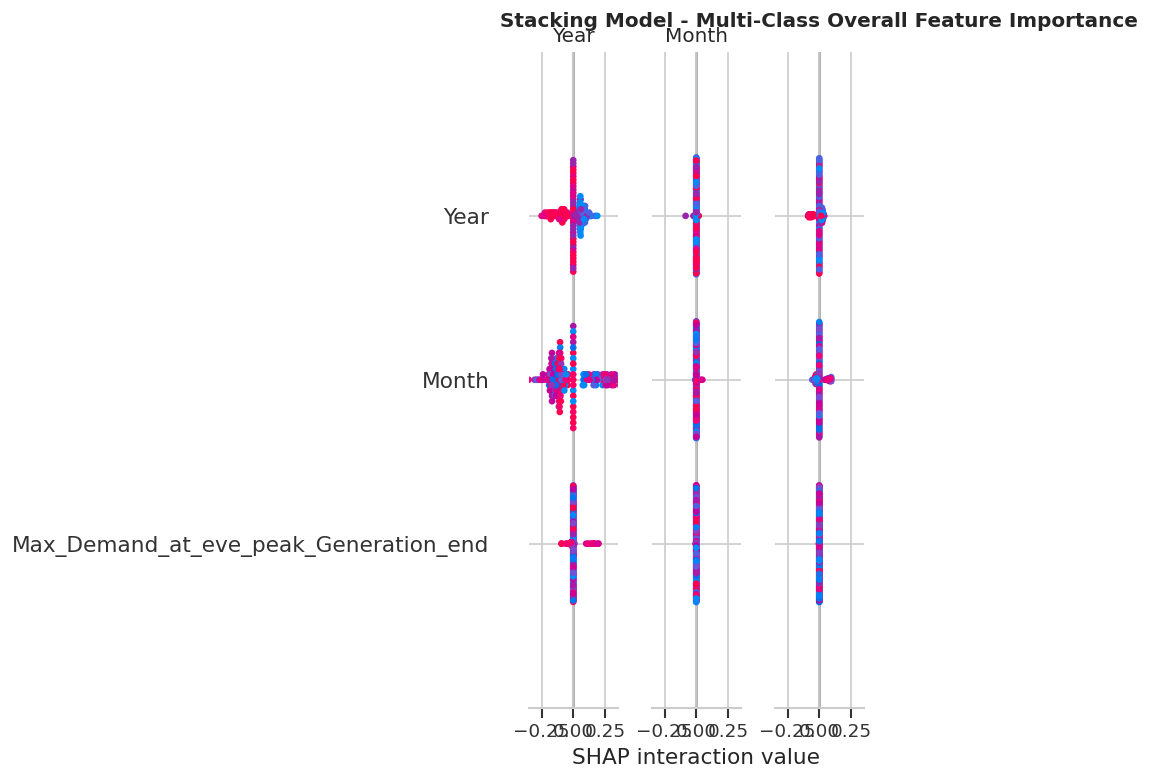

<Figure size 3000x1800 with 0 Axes>

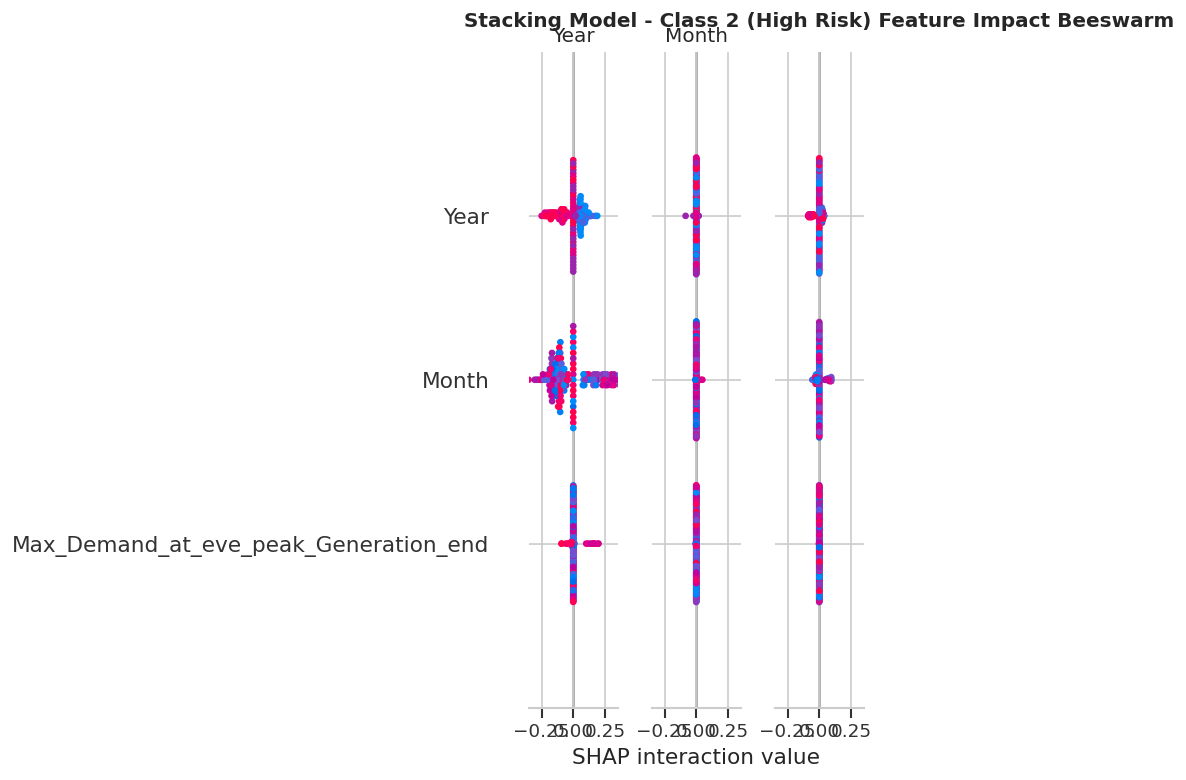


[SUCCESS] Saved 'stacking_shap_multiclass_bar.png' and 'stacking_shap_class2_beeswarm.png'


In [59]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1. Dataset Setup
X_eval_raw = X_test_scaled if 'X_test_scaled' in locals() else X_test
X_eval_df = pd.DataFrame(X_eval_raw, columns=X_train.columns) if not isinstance(X_eval_raw, pd.DataFrame) else X_eval_raw

# Background sample for fast computation
X_background = shap.sample(X_eval_df, min(100, len(X_eval_df)), random_state=42)

# Multi-class KernelExplainer function for Stacking Model
explainer = shap.KernelExplainer(stacking_model.predict_proba, X_background)

# Calculate SHAP values for test sample subset
X_test_sample = shap.sample(X_eval_df, min(200, len(X_eval_df)), random_state=42)
shap_values = explainer.shap_values(X_test_sample)

# 2. Plot 1: Overall Multi-Class Feature Importance (Bar Chart)
plt.figure(figsize=(10, 6), dpi=300)
# shap_values is a list of 3 arrays [Class 0, Class 1, Class 2]
shap.summary_plot(shap_values, X_test_sample, class_names=['Class 0 (Low)', 'Class 1 (Mod)', 'Class 2 (High)'], show=False)
plt.title("Stacking Model - Multi-Class Overall Feature Importance", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("stacking_shap_multiclass_bar.png", bbox_inches='tight', dpi=300)
plt.show()

# 3. Plot 2: Class 2 (High Risk) Specific Beeswarm Summary Plot
# Selecting shap_values[2] for High Risk Class
shap_values_class2 = shap_values[2] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6), dpi=300)
shap.summary_plot(shap_values_class2, X_test_sample, show=False)
plt.title("Stacking Model - Class 2 (High Risk) Feature Impact Beeswarm", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("stacking_shap_class2_beeswarm.png", bbox_inches='tight', dpi=300)
plt.show()

print("\n[SUCCESS] Saved 'stacking_shap_multiclass_bar.png' and 'stacking_shap_class2_beeswarm.png'")

## Automated Output test

REAL-TIME STACKING RISK & SHORTFALL ANALYSIS FOR TEST SAMPLE INDEX: 6
Predicted Risk Level:     Class 2 -> High Risk (Critical)
Class Probabilities:      Low: 0.96%, Mod: 1.43%, High: 97.60%
---------------------------------------------------------------------------
Evening Peak Demand:      0.84 MW
Evening Peak Generation:  0.68 MW
Calculated Shortfall:     0.16 MW


  0%|          | 0/1 [00:00<?, ?it/s]

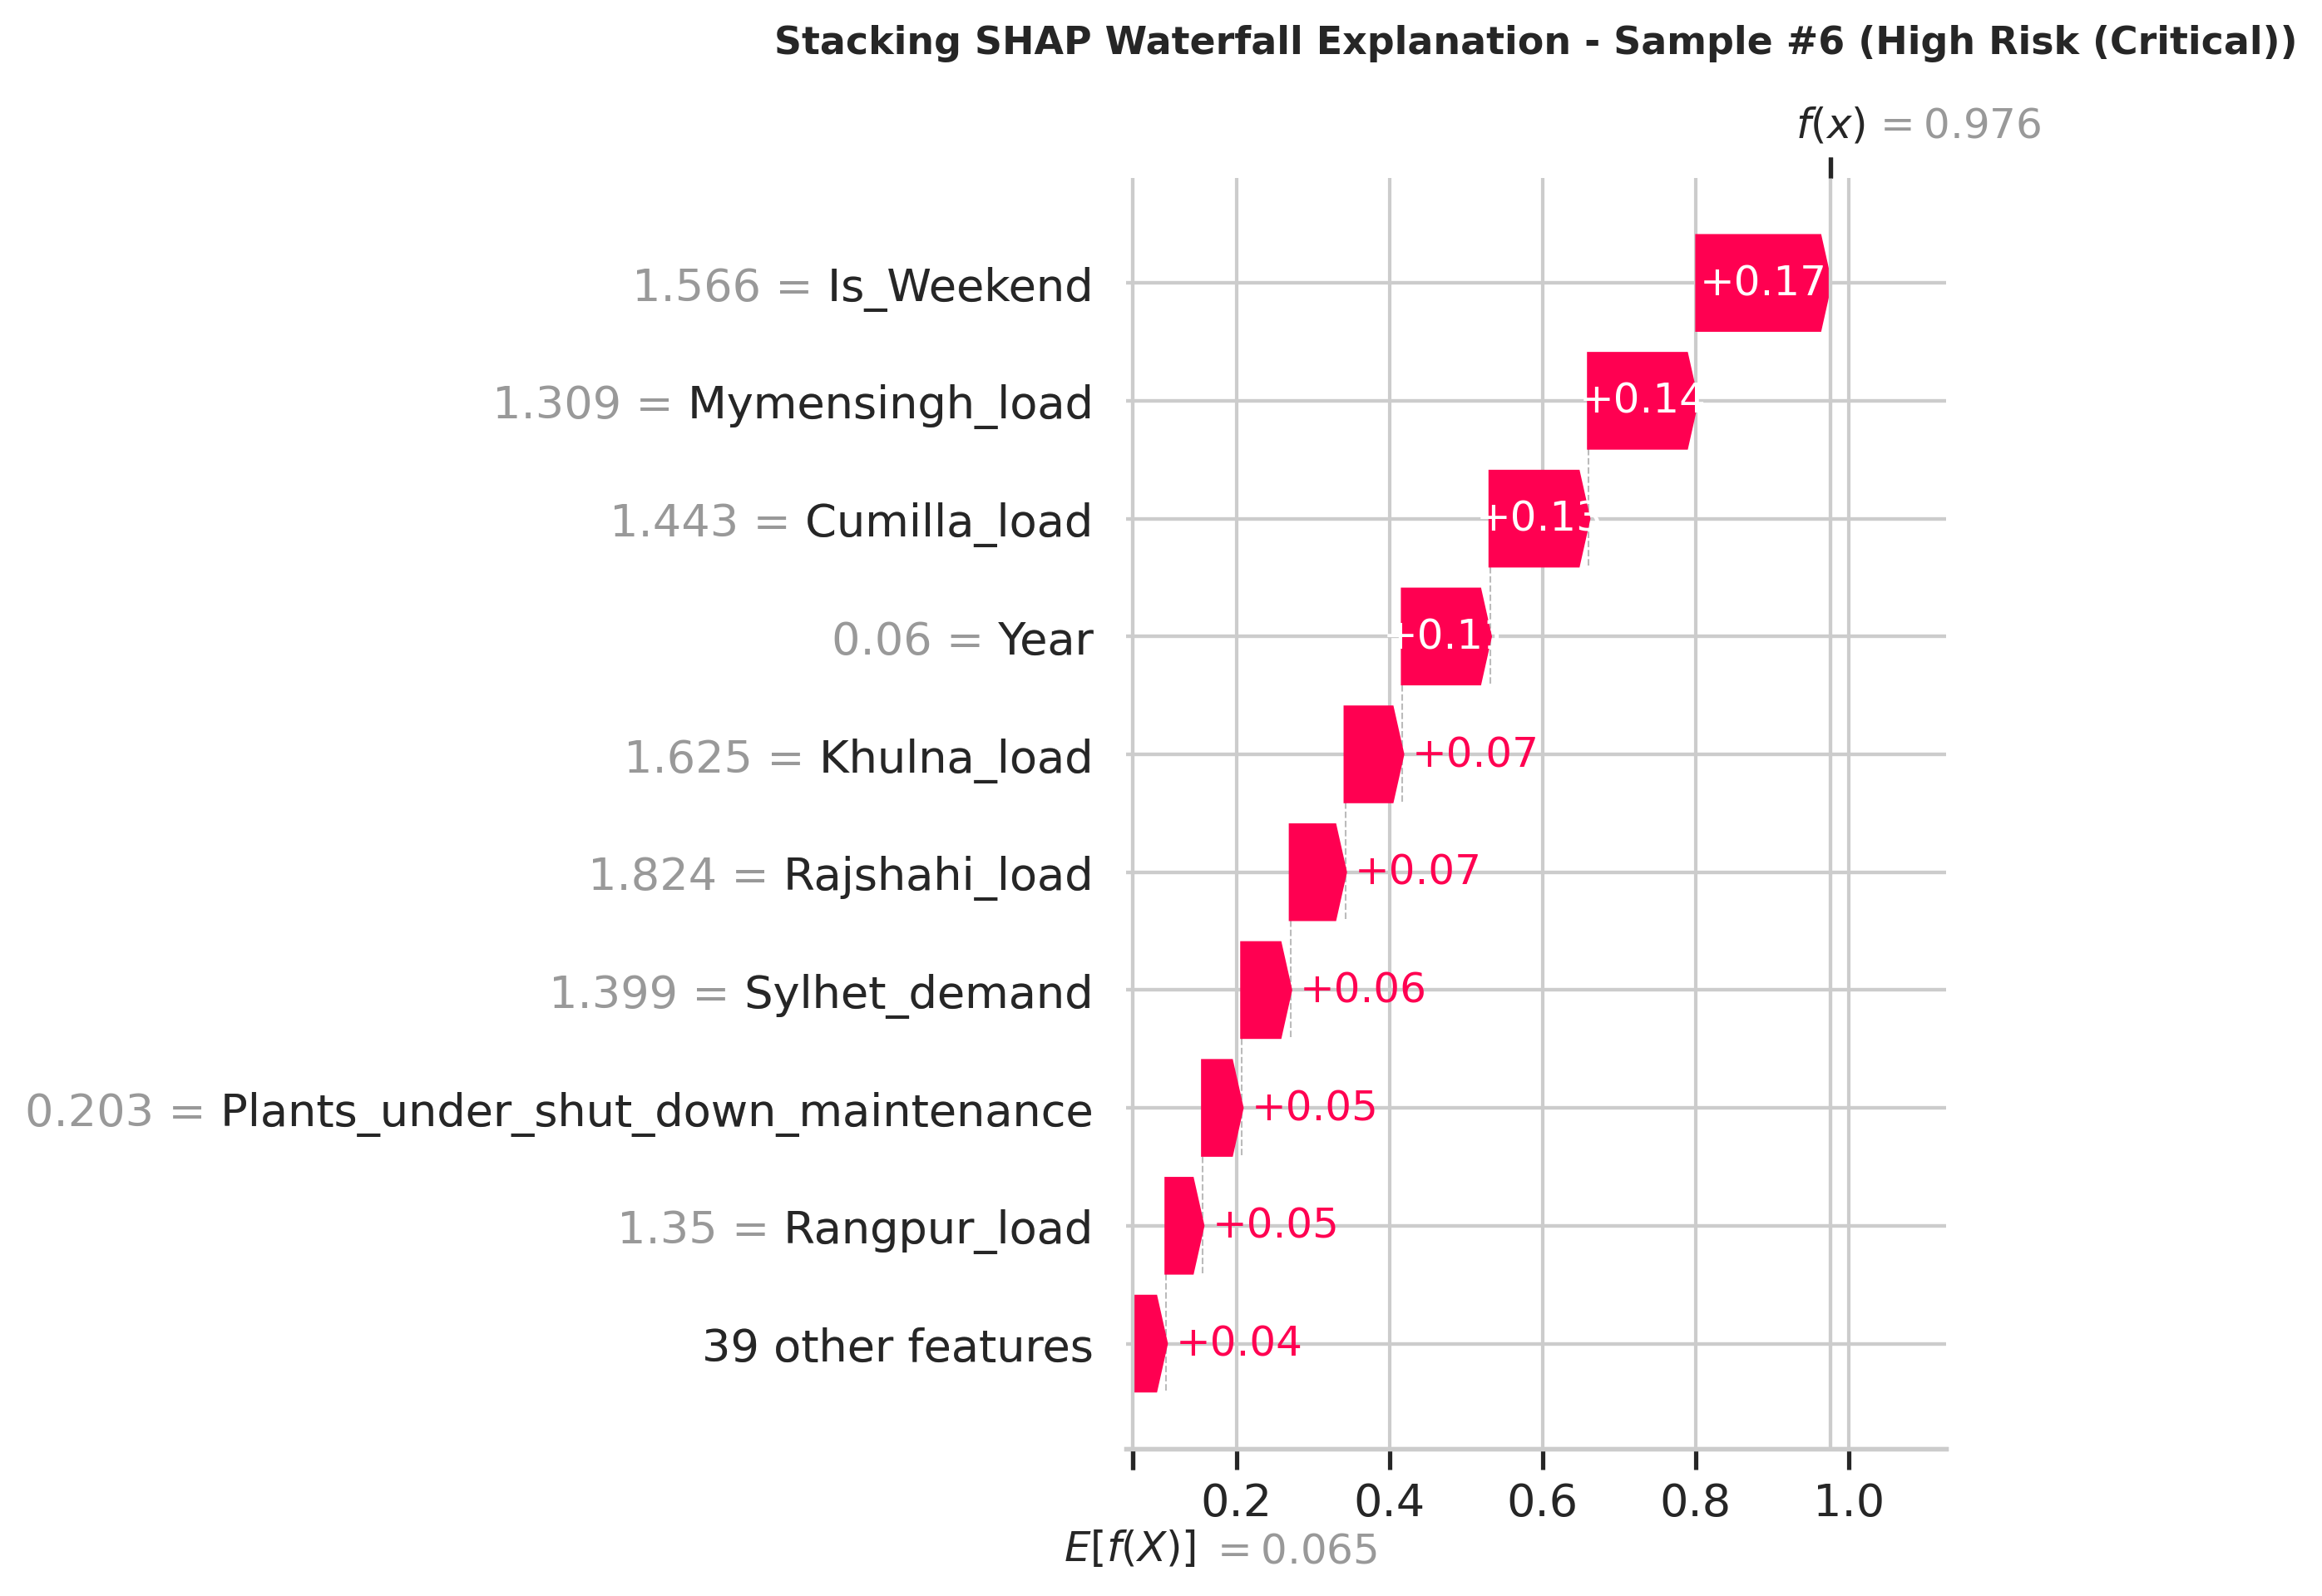


[SUCCESS] Local SHAP waterfall plot saved as 'stacking_local_sample_6_waterfall.png'


In [65]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import re

# Helper function to sanitize column names matching fit-time names
def clean_col_names(df):
    if isinstance(df, pd.DataFrame):
        return df.rename(columns=lambda x: re.sub(r'[^\w\s]', '', str(x)).replace(' ', '_'))
    return df

# Helper function for dynamic single sample evaluation using Stacking Model
def evaluate_stacking_sample_with_shap(sample_index=None):
    # 1. Dataset Setup
    X_eval_raw = X_test_scaled if 'X_test_scaled' in locals() else X_test
    
    # Ensure DataFrame format and cleaned feature names
    if isinstance(X_eval_raw, pd.DataFrame):
        X_eval_df = clean_col_names(X_eval_raw.copy())
    else:
        cleaned_cols = [re.sub(r'[^\w\s]', '', str(c)).replace(' ', '_') for c in X_train.columns]
        X_eval_df = pd.DataFrame(X_eval_raw, columns=cleaned_cols)
    
    # Auto-find a High Risk (Class 2) sample if index is not explicitly provided
    if sample_index is None:
        y_test_arr = y_test.values if isinstance(y_test, (pd.Series, pd.DataFrame)) else np.asarray(y_test)
        high_risk_indices = np.where(y_test_arr == 2)[0]
        if len(high_risk_indices) > 0:
            sample_index = int(high_risk_indices[0])
        else:
            sample_index = 0

    print("="*75)
    print(f"REAL-TIME STACKING RISK & SHORTFALL ANALYSIS FOR TEST SAMPLE INDEX: {sample_index}")
    print("="*75)
    
    # Extract sample
    sample_raw = X_eval_df.iloc[[sample_index]]
    
    # 2. Stacking Model Prediction
    pred_class = int(stacking_model.predict(sample_raw)[0])
    pred_prob = stacking_model.predict_proba(sample_raw)[0]
    
    class_map = {0: "Low Risk (Safe)", 1: "Moderate Risk", 2: "High Risk (Critical)"}
    
    # 3. Exact Shortfall (MW Difference) Calculation with Explicit Column Names
    demand_col = 'Max. Demand at eve. peak (Generation end)'
    gen_col = 'Evening-peak Generation (Generation end)'
    
    # Check if original unscaled X_test / df is available
    if 'X_test' in locals() and isinstance(X_test, pd.DataFrame) and demand_col in X_test.columns:
        orig_row = X_test.iloc[sample_index]
    elif 'df' in locals() and demand_col in df.columns:
        test_idx = X_test.index[sample_index] if 'X_test' in locals() and hasattr(X_test, 'index') else sample_index
        orig_row = df.loc[test_idx]
    else:
        orig_row = sample_raw.iloc[0]

    # Flexible key matching for cleaned or uncleaned column names
    d_val = orig_row[demand_col] if demand_col in orig_row else orig_row.get(re.sub(r'[^\w\s]', '', demand_col).replace(' ', '_'), 0)
    g_val = orig_row[gen_col] if gen_col in orig_row else orig_row.get(re.sub(r'[^\w\s]', '', gen_col).replace(' ', '_'), 0)

    evening_demand = float(d_val)
    evening_gen = float(g_val)
    shortfall_mw = evening_demand - evening_gen
    
    print(f"Predicted Risk Level:     Class {pred_class} -> {class_map[pred_class]}")
    print(f"Class Probabilities:      Low: {pred_prob[0]:.2%}, Mod: {pred_prob[1]:.2%}, High: {pred_prob[2]:.2%}")
    print("-" * 75)
    print(f"Evening Peak Demand:      {evening_demand:.2f} MW")
    print(f"Evening Peak Generation:  {evening_gen:.2f} MW")
    print(f"Calculated Shortfall:     {shortfall_mw:.2f} MW")
    print("="*75)
    
    # 4. Safe Local SHAP Calculation for Waterfall Plot
    if 'explainer' in locals():
        local_explainer = explainer
    else:
        X_background = shap.sample(X_eval_df, min(50, len(X_eval_df)), random_state=42)
        local_explainer = shap.KernelExplainer(stacking_model.predict_proba, X_background)
        
    sample_shap = local_explainer.shap_values(sample_raw)
    
    # Robustly extract 1D target SHAP values and base value for predicted class
    if isinstance(sample_shap, list):
        vals = np.asarray(sample_shap[pred_class]).squeeze()
        base = local_explainer.expected_value[pred_class]
    else:
        vals = np.asarray(sample_shap).squeeze()
        if vals.ndim > 1:
            vals = vals[:, pred_class] if vals.shape[1] == 3 else vals[pred_class, :]
        base = local_explainer.expected_value
        if isinstance(base, (list, np.ndarray)):
            base = base[pred_class]

    # Create Explanation Object with pure 1D array
    exp_obj = shap.Explanation(
        values=vals,
        base_values=float(base),
        data=sample_raw.iloc[0].values,
        feature_names=sample_raw.columns
    )
    
    plt.figure(figsize=(9, 5), dpi=300)
    shap.plots.waterfall(exp_obj, show=False)
    plt.title(f"Stacking SHAP Waterfall Explanation - Sample #{sample_index} ({class_map[pred_class]})", 
              fontsize=11, fontweight='bold', pad=15)
    plt.tight_layout()
    plot_path = f"stacking_local_sample_{sample_index}_waterfall.png"
    plt.savefig(plot_path, bbox_inches='tight', dpi=300)
    plt.show()
    
    print(f"\n[SUCCESS] Local SHAP waterfall plot saved as '{plot_path}'")

# Run test on High Risk Sample (Auto-detected index)
evaluate_stacking_sample_with_shap()

######____Coder: Ataur Rahman, BSc. in EEE from Chtgn Uni of Engieering & Technology. I am Working as an Engineer at Bangladesh telecommunications. I am a Learner who interested in Advanced Research and seeking for Opportunity for funded MS or PHD or RA/TA POssition____________________________***********______________________________*************_____

In [68]:
print("Advanced ML Models Project SUccessfully Completed")
print("09-Oct-2026")

Advanced ML Models Project SUccessfully Completed
09-Oct-2026
